# Soup sprint: SmolLM2-360M → booking-request JSON

Fine-tune `HuggingFaceTB/SmolLM2-360M-Instruct` with **Soup** (LoRA SFT) to turn booking requests into JSON:

```json
{"intent": "reschedule", "date": "2026-12-07", "time": "18:00", "resource": null, "needs_clarification": false}
```

**How to use:** Runtime → Change runtime type → **A100** (High-RAM on). Then run the cells top to bottom.
Everything is written to `MyDrive/soup-sprint/`, so after a disconnect you re-run Phase 0's cells and continue:
finished trainings and predictions are skipped automatically.

**Checks:** every phase ends with a check cell. Each check prints ✅ PASS, ❌ FAIL or 👀 REVIEW (needs your eyes) and
is saved to `reports/checks.json`. Hard checks stop the notebook so nothing builds on a broken step.

| Phase | What | Checks |
|---|---|---|
| 0 | Colab setup, install Soup, write scripts to Drive | 0.1–0.3 |
| 1 | Generate data, fetch replay, tests, data checks | 1.1–1.8 |
| 2 | Baseline: untouched model on val | 2.1–2.4 |
| 3 | Smoke run: 200 rows, 1 epoch | 3.1–3.5 |
| 4 | Full SFT run `sft_v1` | 4.1–4.5 |
| 5 | Hyperparameter study (9 runs), freeze `BEST_RUN` | 5.1–5.5 |
| 6 | Test + stress (once), general-skills check, export | 6.1–6.5 |

**Where this notebook differs from the original plan** (Soup 0.77.2 docs do not cover these):
`soup infer` → `scripts/predict.py` (greedy, loads the LoRA adapter);
`soup eval benchmark` → `lm-eval` directly;
`soup train --yes/--dry-run` → flags are used only if `soup train --help` lists them, else `soup plan`;
adapter folder → found by searching for `adapter_config.json`.
Check 3.4 uses exact_match/schema_valid instead of parse_strict, because the base model already replies with bare JSON.

## Phase 0 — Colab setup (≈ 30 min)

**Steps:** 1) confirm the GPU, 2) mount Drive and create `MyDrive/soup-sprint/`, 3) install `soup-cli[train,eval]`,
4) write all scripts and tests to Drive, 5) run the check cell.

| # | Check | Pass when |
|---|---|---|
| 0.1 | GPU | A GPU is visible and supports bf16 (A100 / H100 / L4) |
| 0.2 | Soup | `soup --version` prints a version (written against 0.77.2); `soup doctor` exits 0 |
| 0.3 | Drive | `MyDrive/soup-sprint/` exists and `reports/pip_freeze.txt` was written |

In [1]:
!nvidia-smi
import sys; print("python", sys.version)

Wed Nov 11 14:59:30 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-80GB          Off |   00000000:00:05.0 Off |                    0 |
| N/A   33C    P0             56W /  400W |       0MiB /  81920MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [2]:
import os
from google.colab import drive
drive.mount("/content/drive")

PROJECT = "/content/drive/MyDrive/soup-sprint"
for d in ["scripts", "tests", "data/eval", "configs", "runs", "reports/preds", "logs", "exports"]:
    os.makedirs(os.path.join(PROJECT, d), exist_ok=True)
os.chdir(PROJECT)
print("working in", os.getcwd())

Mounted at /content/drive
working in /content/drive/MyDrive/soup-sprint


In [3]:
# ~2-4 min. soup-cli needs Python >= 3.11
!pip -q install "soup-cli[train,eval]" pyyaml pytest tabulate
# Colab preinstalls torchao 0.10, which recent peft refuses to load (needs > 0.16).
# Neither Soup nor this project uses torchao (no quantization_aware training), so remove it.
!pip uninstall -y -q torchao
!soup --version

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
soup v0.77.2
https://github.com/MakazhanAlpamys/Soup


### Write the project files to Drive

Each cell below writes one file. They are the same scripts that were tested locally
(35 unit tests, data checks, and an end-to-end CPU run of train → predict → score).

In [4]:
%%writefile scripts/common.py
"""Shared task definition: fields, rules, schema and prompt format."""
from __future__ import annotations

import datetime as dt
import re

INTENTS = ["book", "reschedule", "cancel", "check"]
FIELDS = ["intent", "date", "time", "resource", "needs_clarification"]
REQUIRED = {
    "book": ["date", "time", "resource"],
    "reschedule": ["date", "time"],
    "cancel": ["date"],
    "check": ["date", "resource"],
}
RESOURCES = ["Room A", "Room B", "Room C", "Studio 1", "Studio 2", "Lab 3", "Court 1", "Court 2"]

_DATE_RE = re.compile(r"^\d{4}-\d{2}-\d{2}$")
_TIME_RE = re.compile(r"^([01]\d|2[0-3]):[0-5]\d$")

INSTRUCTION = (
    "Extract the booking request below as JSON. Reply with only a JSON object with exactly these keys: "
    '"intent" (one of "book", "reschedule", "cancel", "check"), '
    '"date" ("YYYY-MM-DD" or null), "time" ("HH:MM", 24-hour, or null), '
    '"resource" (room or facility name, or null), '
    '"needs_clarification" (true if a value the intent needs is missing, else false). '
    "Use null for anything the request does not state."
)


def needs_clarification(rec: dict) -> bool:
    return any(rec.get(f) is None for f in REQUIRED[rec["intent"]])


def build_prompt(request: str, today: dt.date) -> str:
    return f"{INSTRUCTION}\nToday is {today.strftime('%A')}, {today.isoformat()}.\nRequest: {request}"


def label_to_text(label: dict) -> str:
    import json
    return json.dumps({k: label[k] for k in FIELDS}, ensure_ascii=False)


def schema_errors(obj) -> list[str]:
    """Return a list of problems; empty list means schema-valid."""
    errs: list[str] = []
    if not isinstance(obj, dict):
        return ["not_an_object"]
    keys = set(obj)
    if keys != set(FIELDS):
        missing = set(FIELDS) - keys
        extra = keys - set(FIELDS)
        if missing:
            errs.append(f"missing_keys:{sorted(missing)}")
        if extra:
            errs.append(f"extra_keys:{sorted(extra)}")
    if "intent" in obj and obj["intent"] not in INTENTS:
        errs.append("bad_intent")
    if "date" in obj and obj["date"] is not None:
        d = obj["date"]
        ok = isinstance(d, str) and bool(_DATE_RE.match(d))
        if ok:
            try:
                dt.date.fromisoformat(d)
            except ValueError:
                ok = False
        if not ok:
            errs.append("bad_date")
    if "time" in obj and obj["time"] is not None:
        t = obj["time"]
        if not (isinstance(t, str) and _TIME_RE.match(t)):
            errs.append("bad_time")
    if "resource" in obj and obj["resource"] is not None:
        r = obj["resource"]
        if not (isinstance(r, str) and r.strip()):
            errs.append("bad_resource")
    if "needs_clarification" in obj and not isinstance(obj["needs_clarification"], bool):
        errs.append("bad_needs_clarification")
    return errs


def label_errors(label: dict) -> list[str]:
    """Schema check plus the consistency rule, used on generated gold labels."""
    errs = schema_errors(label)
    if not errs and label["needs_clarification"] != needs_clarification(label):
        errs.append("inconsistent_needs_clarification")
    if not errs and label["resource"] is not None and label["resource"] not in RESOURCES:
        errs.append("unknown_resource")
    return errs

Overwriting scripts/common.py


In [5]:
%%writefile scripts/generate_data.py
"""Generate train / val / test / stress splits with rule-computed labels.

Splits are separated by template family: every split uses its own sentence templates.
Usage: python scripts/generate_data.py --out data --seed 1234
"""
from __future__ import annotations

import argparse
import datetime as dt
import hashlib
import json
import os
import random
import re
import sys

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from common import FIELDS, INTENTS, REQUIRED, RESOURCES, build_prompt, label_to_text, needs_clarification  # noqa: E402

# ---------------------------------------------------------------- templates
# "[ ... {slot} ...]" is an optional segment, dropped when the slot is missing.
# Date surfaces include their own preposition ("on December 7", "tomorrow"); time surfaces include "at".
TEMPLATES = {
    "train": {
        "book": [
            "Please book[ {resource}][ {date}][ {time}].",
            "I'd like to reserve[ {resource}][ {date}][ {time}].",
            "Can you get me[ {resource}][ {date}][ {time}]?",
            "Book[ {resource}] for me[ {date}][ {time}] please.",
            "I need a booking[ for {resource}][ {date}][ {time}], can you set that up?",
            "Reserve[ {resource}][ {time}][ {date}] for our team.",
        ],
        "reschedule": [
            "Please move my booking[ for {resource}][ to {date}][ {time}].",
            "Can I change my reservation[ of {resource}][ to {date}][ {time}]?",
            "Reschedule my[ {resource}] slot[ to {date}][ {time}].",
            "I need to shift my appointment[ in {resource}][ to {date}][ {time}].",
            "Push my booking[ for {resource}] back[ to {date}][ {time}].",
            "Could we move it[ to {date}][ {time}] instead?[ It's the {resource} booking.]",
        ],
        "cancel": [
            "Please cancel my booking[ for {resource}][ {date}][ {time}].",
            "Cancel the[ {resource}] reservation[ {date}][ {time}].",
            "I won't need my booking[ of {resource}][ {date}][ {time}] anymore, please cancel it.",
            "Drop my reservation[ {date}][ {time}][ for {resource}].",
            "Can you call off my booking[ in {resource}][ {date}][ {time}]?",
            "Remove my[ {resource}] slot[ {date}][ {time}] from the calendar.",
        ],
        "check": [
            "Is there availability[ in {resource}][ {date}][ {time}]?",
            "Can you check availability[ for {resource}][ {date}][ {time}]?",
            "Do you have any openings[ in {resource}][ {date}][ {time}]?",
            "What's the availability[ of {resource}][ {date}][ {time}]?",
            "Any free slots[ for {resource}][ {date}][ {time}]?",
            "I want to know whether there is space[ in {resource}][ {date}][ {time}].",
        ],
    },
    "val": {
        "book": [
            "Could I grab a slot[ in {resource}][ {date}][ {time}]?",
            "Hold[ {resource}] for us[ {date}][ {time}].",
        ],
        "reschedule": [
            "Something came up, can we do[ {date}][ {time}] instead for my[ {resource}] reservation?",
            "Let's change the time of my booking[ in {resource}][ to {date}][ {time}].",
        ],
        "cancel": [
            "We no longer need the booking[ for {resource}][ {date}][ {time}], scrap it.",
            "Kindly delete my reservation[ of {resource}][ {date}][ {time}].",
        ],
        "check": [
            "Would there be room[ in {resource}][ {date}][ {time}]?",
            "Look up if anything is open[ in {resource}][ {date}][ {time}].",
        ],
    },
    "test": {
        "book": [
            "We would like a reservation[ for {resource}][ {date}][ {time}] please.",
            "Set up a booking[ for {resource}][ {date}][ {time}] if possible.",
        ],
        "reschedule": [
            "Is it possible to postpone my[ {resource}] booking[ until {date}][ {time}]?",
            "I'd prefer[ {date}][ {time}] for my[ {resource}] reservation instead of the current one.",
        ],
        "cancel": [
            "Our plans changed so please release the[ {resource}] booking[ {date}][ {time}].",
            "Forget about my reservation[ for {resource}][ {date}][ {time}], it's cancelled.",
        ],
        "check": [
            "Is there a vacancy[ for {resource}][ {date}][ {time}]?",
            "Please find out if a spot is available[ in {resource}][ {date}][ {time}].",
        ],
    },
}
TEMPLATES["stress"] = TEMPLATES["test"]  # same families as test, plus noise and unseen wording

SPLIT_CFG = {  # rows, probability that >=1 required field is missing, use unseen surface forms
    "train": dict(n=2000, p_missing=0.28, stress=False),
    "val": dict(n=300, p_missing=0.30, stress=False),
    "test": dict(n=300, p_missing=0.50, stress=False),
    "stress": dict(n=150, p_missing=0.50, stress=True),
}

MONTHS = ["January", "February", "March", "April", "May", "June", "July",
          "August", "September", "October", "November", "December"]
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
NUM_WORDS = {1: "one", 2: "two", 3: "three", 4: "four", 5: "five", 6: "six", 7: "seven", 8: "eight",
             9: "nine", 10: "ten", 11: "eleven", 12: "twelve"}


def ordinal(n: int) -> str:
    suf = "th" if 10 <= n % 100 <= 20 else {1: "st", 2: "nd", 3: "rd"}.get(n % 10, "th")
    return f"{n}{suf}"


# ---------------------------------------------------------------- date rules
def next_weekday(today: dt.date, weekday: int) -> dt.date:
    """Rule: 'next <Weekday>' = the first such day strictly after today."""
    delta = (weekday - today.weekday()) % 7
    return today + dt.timedelta(days=delta or 7)


def date_surface(today: dt.date, rng: random.Random, stress: bool) -> tuple[str, str]:
    base_forms = ["today", "tomorrow", "day_after", "in_n_days", "next_weekday",
                  "month_day", "day_month", "iso", "ordinal_of"]
    stress_forms = ["week_from_today", "two_weeks", "in_n_days_words", "abbr_dot", "day_abbr"]
    form = rng.choice(stress_forms if (stress and rng.random() < 0.7) else base_forms)
    if form == "today":
        return "today", today.isoformat()
    if form == "tomorrow":
        return "tomorrow", (today + dt.timedelta(days=1)).isoformat()
    if form == "day_after":
        return "the day after tomorrow", (today + dt.timedelta(days=2)).isoformat()
    if form == "in_n_days":
        n = rng.randint(2, 14)
        return f"in {n} days", (today + dt.timedelta(days=n)).isoformat()
    if form == "next_weekday":
        w = rng.randrange(7)
        return f"next {WEEKDAYS[w]}", next_weekday(today, w).isoformat()
    if form == "week_from_today":
        return "a week from today", (today + dt.timedelta(days=7)).isoformat()
    if form == "two_weeks":
        return "two weeks from today", (today + dt.timedelta(days=14)).isoformat()
    if form == "in_n_days_words":
        n = rng.randint(2, 10)
        return f"in {NUM_WORDS[n]} days", (today + dt.timedelta(days=n)).isoformat()
    # absolute dates: always within the next 1..90 days, so "December 7" has one meaning
    target = today + dt.timedelta(days=rng.randint(1, 90))
    m, d = MONTHS[target.month - 1], target.day
    surface = {
        "month_day": f"on {m} {d}",
        "day_month": f"on {d} {m}",
        "iso": f"on {target.isoformat()}",
        "ordinal_of": f"on the {ordinal(d)} of {m}",
        "abbr_dot": f"on {m[:3]}. {ordinal(d)}",
        "day_abbr": f"on {ordinal(d)} {m[:3]}",
    }[form]
    return surface, target.isoformat()


# ---------------------------------------------------------------- time rules
def _h12(h: int) -> tuple[int, str]:
    return (h % 12 or 12), ("am" if h < 12 else "pm")


def _part_of_day(h: int) -> str:
    return "in the morning" if h < 12 else ("in the afternoon" if h < 17 else "in the evening")


def time_surface(rng: random.Random, stress: bool) -> tuple[str, str]:
    h = rng.randint(7, 21)
    m = rng.choice([0, 0, 0, 30, 30, 15, 45])
    iso = f"{h:02d}:{m:02d}"
    h12, ap = _h12(h)
    base = ["h24", "ampm", "ampm_space", "oclock", "noon"]
    strs = ["half_past", "quarter", "military", "dotted", "midday"]
    order = (strs if (stress and rng.random() < 0.7) else base)[:]
    rng.shuffle(order)
    for form in order + ["h24"]:
        if form == "h24":
            return f"at {iso}", iso
        if form == "ampm":
            return (f"at {h12}{ap}" if m == 0 else f"at {h12}:{m:02d}{ap}"), iso
        if form == "ampm_space":
            return (f"at {h12} {ap}" if m == 0 else f"at {h12}:{m:02d} {ap}"), iso
        if form == "oclock" and m == 0:
            return f"at {h12} o'clock {_part_of_day(h)}", iso
        if form == "noon" and h == 12 and m == 0:
            return "at noon", iso
        if form == "midday" and h == 12 and m == 0:
            return "at midday", iso
        if form == "half_past" and m == 30:
            return f"at half past {NUM_WORDS[h12]} {_part_of_day(h)}", iso
        if form == "quarter" and m == 15:
            return f"at quarter past {NUM_WORDS[h12]} {_part_of_day(h)}", iso
        if form == "quarter" and m == 45:
            nh12, _ = _h12(h + 1)
            return f"at quarter to {NUM_WORDS[nh12]} {_part_of_day(h + 1)}", iso
        if form == "military":
            return f"at {h:02d}{m:02d}h", iso
        if form == "dotted":
            return f"at {h12}.{m:02d} {'a.m.' if ap == 'am' else 'p.m.'}", iso
    raise AssertionError("unreachable")


# ---------------------------------------------------------------- resource rules
def resource_surface(rng: random.Random, stress: bool) -> tuple[str, str]:
    res = rng.choice(RESOURCES)
    kind, ident = res.split(" ")
    if stress and rng.random() < 0.7:
        word = NUM_WORDS[int(ident)] if ident.isdigit() else ident
        forms = {
            "Room": [f"rm {ident}", f"room-{ident}"],
            "Studio": [f"studio {word}", f"studio no. {ident}"],
            "Lab": [f"laboratory {ident}", f"lab no. {ident}"],
            "Court": [f"court no. {ident}", f"court {word}"],
        }[kind]
        return rng.choice(forms), res
    return rng.choice([res, res, f"{kind.lower()} {ident}"]), res


# ---------------------------------------------------------------- rendering
_SEG_RE = re.compile(r"\[([^\]]*)\]")
_SLOT_RE = re.compile(r"\{(\w+)\}")


def render(template: str, surfaces: dict) -> list[tuple[str, bool]]:
    """Render to segments [(text, is_slot)]. Missing slots drop their optional segment."""
    pieces: list[tuple[str, bool]] = []
    pos = 0
    for m in _SEG_RE.finditer(template):
        pieces.extend(_render_plain(template[pos:m.start()], surfaces))
        inner = m.group(1)
        slots = _SLOT_RE.findall(inner)
        if all(surfaces.get(s) is not None for s in slots):
            pieces.extend(_render_plain(inner, surfaces))
        pos = m.end()
    pieces.extend(_render_plain(template[pos:], surfaces))
    return pieces


def _render_plain(text: str, surfaces: dict) -> list[tuple[str, bool]]:
    out, pos = [], 0
    for m in _SLOT_RE.finditer(text):
        out.append((text[pos:m.start()], False))
        out.append((surfaces[m.group(1)], True))
        pos = m.end()
    out.append((text[pos:], False))
    return [p for p in out if p[0]]


def clean(text: str) -> str:
    text = re.sub(r"\s+", " ", text).strip()
    text = re.sub(r"\s+([.,?!])", r"\1", text)
    # "to on December 7" -> "to December 7";  "to in 3 days" -> "in 3 days"
    text = re.sub(r"\b(to|until) on\b", r"\1", text, flags=re.I)
    text = re.sub(r"\b(?:to|until) (in \w+ days)\b", r"\1", text, flags=re.I)
    return text[0].upper() + text[1:] if text else text


# ---------------------------------------------------------------- noise (stress only)
FILLERS_PRE = ["hey,", "hi there!", "um so", "hello,", "ok so", "quick one:"]
FILLERS_POST = ["thanks!", "cheers", "asap pls", "thank you so much", "ty"]


def _typo(word: str, rng: random.Random) -> str:
    if len(word) < 4 or not word.isalpha():
        return word
    i = rng.randrange(len(word) - 1)
    op = rng.choice(["swap", "drop", "double"])
    if op == "swap":
        return word[:i] + word[i + 1] + word[i] + word[i + 2:]
    if op == "drop":
        return word[:i] + word[i + 1:]
    return word[:i] + word[i] + word[i:]


def add_noise(segments: list[tuple[str, bool]], rng: random.Random) -> str:
    segs = [list(s) for s in segments]
    if rng.random() < 0.5:  # 1-2 typos, only in template words (never inside a slot value)
        cand = [(i, j) for i, (t, slot) in enumerate(segs) if not slot
                for j, w in enumerate(t.split(" ")) if len(w) >= 4 and w.isalpha()]
        for i, j in rng.sample(cand, k=min(len(cand), rng.randint(1, 2))):
            words = segs[i][0].split(" ")
            words[j] = _typo(words[j], rng)
            segs[i][0] = " ".join(words)
    text = clean("".join(t for t, _ in segs))
    if rng.random() < 0.4:
        text = f"{rng.choice(FILLERS_PRE)} {text[0].lower()}{text[1:]}"
    if rng.random() < 0.4:
        text = f"{text} {rng.choice(FILLERS_POST)}"
    r = rng.random()
    if r < 0.15:
        text = text.upper()
    elif r < 0.35:
        text = text.lower()
    return text


# ---------------------------------------------------------------- sampling
def sample_presence(intent: str, p_missing: float, rng: random.Random) -> dict:
    req = REQUIRED[intent]
    present = {f: True for f in ["date", "time", "resource"]}
    for f in ["date", "time", "resource"]:
        if f not in req:
            present[f] = rng.random() < 0.5  # optional fields: 50/50
    if rng.random() < p_missing:
        k = 1 if (len(req) == 1 or rng.random() < 0.75) else rng.randint(2, len(req))
        for f in rng.sample(req, k):
            present[f] = False
    return present


def make_row(split: str, rng: random.Random, start: dt.date) -> dict:
    cfg = SPLIT_CFG[split]
    intent = rng.choice(INTENTS)
    t_idx = rng.randrange(len(TEMPLATES[split][intent]))
    template = TEMPLATES[split][intent][t_idx]
    today = start + dt.timedelta(days=rng.randrange(730))
    present = sample_presence(intent, cfg["p_missing"], rng)
    label = {"intent": intent, "date": None, "time": None, "resource": None}
    surfaces = {}
    if present["date"]:
        surfaces["date"], label["date"] = date_surface(today, rng, cfg["stress"])
    if present["time"]:
        surfaces["time"], label["time"] = time_surface(rng, cfg["stress"])
    if present["resource"]:
        surfaces["resource"], label["resource"] = resource_surface(rng, cfg["stress"])
    label["needs_clarification"] = needs_clarification(label)
    segments = render(template, surfaces)
    request = add_noise(segments, rng) if cfg["stress"] else clean("".join(t for t, _ in segments))
    family = f"{'test' if split == 'stress' else split}/{intent}/{t_idx}"
    return {
        "split": split, "template": family, "today": today.isoformat(), "request": request,
        "prompt": build_prompt(request, today), "label": {k: label[k] for k in FIELDS},
    }


def generate(seed: int = 1234) -> dict[str, list[dict]]:
    rng = random.Random(seed)
    start = dt.date(2026, 1, 1)
    seen: set[str] = set()
    out: dict[str, list[dict]] = {}
    for split in ["train", "val", "test", "stress"]:
        rows, tries = [], 0
        while len(rows) < SPLIT_CFG[split]["n"]:
            tries += 1
            if tries > 200_000:
                raise RuntimeError(f"could not generate enough unique rows for {split}")
            row = make_row(split, rng, start)
            key = re.sub(r"\W+", " ", row["request"].lower()).strip()
            if key in seen:  # no request text is shared across (or within) splits
                continue
            seen.add(key)
            row["id"] = f"{split}-{len(rows):04d}"
            rows.append(row)
        out[split] = rows
    return out


def sha256(path: str) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 16), b""):
            h.update(chunk)
    return h.hexdigest()


def write_jsonl(path: str, rows: list[dict]) -> None:
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        for r in rows:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--out", default="data")
    ap.add_argument("--seed", type=int, default=1234)
    args = ap.parse_args()
    splits = generate(args.seed)
    # train.jsonl holds only chat messages (what Soup trains on); metadata goes to a sidecar file
    train_chat = [{"messages": [{"role": "user", "content": r["prompt"]},
                                {"role": "assistant", "content": label_to_text(r["label"])}]}
                  for r in splits["train"]]
    files = {
        "train.jsonl": train_chat,
        "train_meta.jsonl": splits["train"],
        "eval/val.jsonl": splits["val"],
        "eval/test.jsonl": splits["test"],
        "eval/stress.jsonl": splits["stress"],
    }
    for rel, rows in files.items():
        write_jsonl(os.path.join(args.out, rel), rows)
    manifest = {"seed": args.seed,
                "files": {rel: {"rows": len(rows), "sha256": sha256(os.path.join(args.out, rel))}
                          for rel, rows in files.items()}}
    with open(os.path.join(args.out, "manifest.json"), "w") as f:
        json.dump(manifest, f, indent=2)
    for rel, info in manifest["files"].items():
        print(f"{rel:22s} {info['rows']:5d} rows  sha256={info['sha256'][:12]}…")


if __name__ == "__main__":
    main()

Overwriting scripts/generate_data.py


In [6]:
%%writefile scripts/fetch_replay.py
"""Download general-chat replay rows from HuggingFaceTB/smol-smoltalk (smol-magpie-ultra-short).

Replay rows are mixed into training to limit forgetting; they are never scored.
Usage: python scripts/fetch_replay.py --out data/replay.jsonl --n 300
"""
from __future__ import annotations

import argparse
import json
import os
import random
import sys

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))

DATASET = "HuggingFaceTB/smol-smoltalk"
SOURCE = "smol-magpie-ultra-short"


def filter_replay_row(row: dict, max_chars: int = 1800) -> dict | None:
    """First user -> assistant exchange of a SOURCE chat (magpie chats are usually multi-turn);
    system prompts dropped; None = reject."""
    if row.get("source") != SOURCE:
        return None
    msgs = [m for m in (row.get("messages") or []) if m.get("role") != "system"][:2]
    if len(msgs) != 2 or msgs[0].get("role") != "user" or msgs[1].get("role") != "assistant":
        return None
    user = (msgs[0].get("content") or "").strip()
    asst = (msgs[1].get("content") or "").strip()
    if not user or not asst or len(user) + len(asst) > max_chars:
        return None
    return {"messages": [{"role": "user", "content": user}, {"role": "assistant", "content": asst}]}


def select_replay(rows, n: int, seed: int = 0, max_chars: int = 1800) -> list[dict]:
    kept = [r for r in (filter_replay_row(x, max_chars) for x in rows) if r is not None]
    if len(kept) < n:
        raise RuntimeError(f"only {len(kept)} replay rows passed the filter, need {n}")
    return random.Random(seed).sample(kept, n)


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--out", default="data/replay.jsonl")
    ap.add_argument("--n", type=int, default=300)
    ap.add_argument("--seed", type=int, default=0)
    args = ap.parse_args()

    from datasets import load_dataset  # imported here so the tests don't need `datasets`
    ds = load_dataset(DATASET, split="train")
    if "source" not in ds.column_names:
        raise RuntimeError(f"{DATASET} has no 'source' column: {ds.column_names}")
    ds = ds.filter(lambda s: s == SOURCE, input_columns="source")
    print(f"{len(ds)} rows with source={SOURCE}")
    if len(ds) == 0:
        raise RuntimeError(f"no rows with source={SOURCE}; values seen: {sorted(set(load_dataset(DATASET, split='test')['source']))}")
    rows = select_replay(ds, args.n, args.seed)

    os.makedirs(os.path.dirname(args.out) or ".", exist_ok=True)
    with open(args.out, "w", encoding="utf-8") as f:
        for r in rows:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")

    # record the file in the data manifest next to it
    from generate_data import sha256
    data_dir = os.path.dirname(args.out) or "."
    mpath = os.path.join(data_dir, "manifest.json")
    manifest = json.load(open(mpath)) if os.path.exists(mpath) else {"files": {}}
    rel = os.path.relpath(args.out, data_dir).replace(os.sep, "/")
    manifest["files"][rel] = {"rows": len(rows), "sha256": sha256(args.out)}
    with open(mpath, "w") as f:
        json.dump(manifest, f, indent=2)
    print(f"wrote {len(rows)} rows to {args.out}")


if __name__ == "__main__":
    main()

Overwriting scripts/fetch_replay.py


In [7]:
%%writefile scripts/check_data.py
"""Phase 1 data checks 1.2-1.6 (+ replay), and prints 10 random rows for check 1.8.

Exit code 1 if any check fails. Writes a summary to reports/data_checks.json.
Usage: python scripts/check_data.py --data data --reports reports
"""
from __future__ import annotations

import argparse
import itertools
import json
import os
import random
import re
import sys

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from common import INTENTS, label_errors  # noqa: E402
from generate_data import sha256  # noqa: E402

EVAL_SPLITS = ["val", "test", "stress"]


def load_jsonl(path: str) -> list[dict]:
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


def norm(text: str) -> str:
    return re.sub(r"\W+", " ", text.lower()).strip()


def chat_ok(row: dict) -> bool:
    msgs = row.get("messages")
    return (isinstance(msgs, list) and len(msgs) == 2
            and [m.get("role") for m in msgs] == ["user", "assistant"]
            and all(isinstance(m.get("content"), str) and m["content"].strip() for m in msgs))


def run_checks(data: str) -> list[dict]:
    results: list[dict] = []

    def check(cid: str, name: str, ok: bool, detail: str) -> None:
        results.append({"id": cid, "name": name, "ok": bool(ok), "detail": detail})
        print(f"{'PASS' if ok else 'FAIL'}  {cid:5s} {name:28s} {detail}")

    train = load_jsonl(os.path.join(data, "train.jsonl"))
    meta = load_jsonl(os.path.join(data, "train_meta.jsonl"))
    evals = {s: load_jsonl(os.path.join(data, "eval", f"{s}.jsonl")) for s in EVAL_SPLITS}

    # 1.2 structure -------------------------------------------------------------
    bad = [i for i, r in enumerate(train) if not chat_ok(r)]
    aligned = len(train) == len(meta) and all(
        r["messages"][0]["content"] == m["prompt"] for r, m in zip(train, meta))
    check("1.2", "structure", not bad and aligned and len(train) == 2000,
          f"{len(train)} train rows, {len(bad)} malformed, meta aligned={aligned}")

    # 1.3 labels ----------------------------------------------------------------
    labels: dict[str, list[dict]] = {"train": []}
    parse_fail = 0
    for r in train:
        try:
            labels["train"].append(json.loads(r["messages"][1]["content"]))
        except (json.JSONDecodeError, KeyError, IndexError):
            parse_fail += 1
    for s in EVAL_SPLITS:
        labels[s] = [r["label"] for r in evals[s]]
    total = sum(len(v) for v in labels.values())
    invalid = [(s, i, label_errors(lab)) for s, v in labels.items() for i, lab in enumerate(v) if label_errors(lab)]
    train_match = all(lab == m["label"] for lab, m in zip(labels["train"], meta))
    check("1.3", "labels pass schema", parse_fail == 0 and not invalid and train_match and total == 2750,
          f"{total} labels, {parse_fail} unparseable, {len(invalid)} invalid {invalid[:3]}, meta match={train_match}")

    # 1.4 leakage ---------------------------------------------------------------
    rows = {"train": meta, **evals}
    prompts = {s: {r["prompt"] for r in v} for s, v in rows.items()}
    requests = {s: {norm(r["request"]) for r in v} for s, v in rows.items()}
    shared = {f"{a}&{b}": len(prompts[a] & prompts[b]) + len(requests[a] & requests[b])
              for a, b in itertools.combinations(rows, 2)}
    fams = {s: {r["template"] for r in v} for s, v in rows.items()}
    fam_disjoint = not (fams["train"] & fams["val"] or fams["train"] & fams["test"] or fams["val"] & fams["test"])
    stress_in_test = fams["stress"] <= fams["test"]
    check("1.4", "no leakage", sum(shared.values()) == 0 and fam_disjoint and stress_in_test,
          f"shared prompts/requests={shared}, families disjoint={fam_disjoint}, stress⊆test={stress_in_test}")

    # 1.5 coverage --------------------------------------------------------------
    cov = {}
    ok = True
    for s, v in labels.items():
        intents = {lab["intent"] for lab in v}
        share = sum(lab["needs_clarification"] for lab in v) / len(v)
        cov[s] = f"{len(intents)} intents, missing={share:.0%}"
        ok &= intents == set(INTENTS) and 0.10 <= share <= 0.60
    check("1.5", "coverage", ok, "; ".join(f"{s}: {c}" for s, c in cov.items()))

    # 1.6 checksums -------------------------------------------------------------
    manifest = json.load(open(os.path.join(data, "manifest.json")))
    mism = [rel for rel, info in manifest["files"].items()
            if not os.path.exists(os.path.join(data, rel)) or sha256(os.path.join(data, rel)) != info["sha256"]]
    check("1.6", "checksums", not mism, f"{len(manifest['files'])} files in manifest, mismatched={mism}")

    # replay (structure only; never scored) --------------------------------------
    rpath = os.path.join(data, "replay.jsonl")
    if os.path.exists(rpath):
        replay = load_jsonl(rpath)
        need = round(0.1 / 0.9 * len(train))  # Soup: n_replay = round(r/(1-r) * n_new)
        rbad = sum(not chat_ok(r) for r in replay)
        overlap = len({r["messages"][0]["content"] for r in replay} & prompts["train"])
        check("1.R", "replay file", rbad == 0 and len(replay) >= need and overlap == 0,
              f"{len(replay)} rows (Soup needs {need} at ratio 0.1), {rbad} malformed, {overlap} overlap with train")
    else:
        check("1.R", "replay file", False, f"{rpath} missing (run fetch_replay.py)")

    # 1.8 rows to read by eye ----------------------------------------------------
    rng = random.Random()
    pool = [("train", m) for m in meta] + [(s, r) for s in EVAL_SPLITS for r in evals[s]]
    print("\n1.8  Read these 10 random rows — each label should be obviously right:")
    for s, r in rng.sample(pool, 10):
        print(f"[{s:6s}] today={r['today']} ({__import__('datetime').date.fromisoformat(r['today']).strftime('%a')})"
              f" | {r['request']}\n         -> {json.dumps(r['label'])}")
    return results


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--data", default="data")
    ap.add_argument("--reports", default="reports")
    args = ap.parse_args()
    results = run_checks(args.data)
    os.makedirs(args.reports, exist_ok=True)
    with open(os.path.join(args.reports, "data_checks.json"), "w") as f:
        json.dump(results, f, indent=2)
    failed = [r["id"] for r in results if not r["ok"]]
    print(f"\n{len(results) - len(failed)}/{len(results)} data checks passed" + (f"; FAILED: {failed}" if failed else ""))
    sys.exit(1 if failed else 0)


if __name__ == "__main__":
    main()

Overwriting scripts/check_data.py


In [8]:
%%writefile scripts/evaluate.py
"""Score model replies against gold labels.

Metrics (all in %): exact_match (primary, with bootstrap CI95), schema_valid, parse_strict,
parse_lenient, field_<name>, and exact_match by intent and by complete/missing group.
With --pred-b, also the paired difference exact_match(A) - exact_match(B) on the same rows, with CI95.

Usage:
  python scripts/evaluate.py --gold data/eval/val.jsonl --pred reports/base_val.pred.jsonl \
      --out reports/base_val.json [--pred-b reports/other.pred.jsonl]
Prediction files are JSONL with {"id": ..., "response": "..."}; missing ids score as failures.
"""
from __future__ import annotations

import argparse
import json
import os
import random
import re
import sys
from collections import Counter

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from common import FIELDS, INTENTS, schema_errors  # noqa: E402

N_BOOT = 2000


# ---------------------------------------------------------------- parsing
def parse_strict(text: str):
    """The reply is a JSON object and nothing else (surrounding whitespace allowed)."""
    try:
        obj = json.loads(text.strip())
    except (json.JSONDecodeError, TypeError, AttributeError):
        return None
    return obj if isinstance(obj, dict) else None


def parse_lenient(text: str):
    """First JSON object found anywhere in the reply (e.g. inside ```json fences or after prose)."""
    obj = parse_strict(text)
    if obj is not None:
        return obj
    if not isinstance(text, str):
        return None
    dec = json.JSONDecoder()
    for m in re.finditer(r"\{", text):
        try:
            obj, _ = dec.raw_decode(text, m.start())
        except json.JSONDecodeError:
            continue
        if isinstance(obj, dict):
            return obj
    return None


def same_value(a, b) -> bool:
    """Equal with the same type, so True != 1 and "null" != None."""
    return type(a) is type(b) and a == b


# ---------------------------------------------------------------- per-row scoring
def score_row(response: str, gold: dict) -> dict:
    strict = parse_strict(response)
    obj = parse_lenient(response)
    errs = schema_errors(obj) if obj is not None else ["no_json"]
    fields = {f: obj is not None and f in obj and same_value(obj[f], gold[f]) for f in FIELDS}
    exact = not errs and all(fields.values())
    return {
        "parse_strict": strict is not None,
        "parse_lenient": obj is not None,
        "schema_valid": not errs,
        "exact_match": exact,
        **{f"field_{f}": v for f, v in fields.items()},
        "_parsed": obj,
        "_schema_errors": errs,
    }


def error_types(response: str, gold: dict, s: dict) -> list[str]:
    """Nameable failure causes, for reading errors (checks 2.4 / 4.5)."""
    if s["exact_match"]:
        return []
    types = []
    if not s["parse_lenient"]:
        return ["no_json"]
    if not s["parse_strict"]:
        types.append("extra_text")
    obj = s["_parsed"]
    if any(isinstance(obj.get(f), str) and obj[f].strip().lower() in ("null", "none", "") for f in FIELDS):
        types.append("null_as_text")
    if any(e.startswith(("missing_keys", "extra_keys")) for e in s["_schema_errors"]):
        types.append("wrong_keys")
    for f in FIELDS:
        if not s[f"field_{f}"]:
            if f in obj and obj[f] is not None and gold[f] is None:
                types.append(f"{f}_invented")       # value given where request had none
            elif (f not in obj or obj[f] is None) and gold[f] is not None:
                types.append(f"{f}_missed")
            else:
                types.append(f"{f}_wrong")
    return types or ["other"]


# ---------------------------------------------------------------- statistics
def bootstrap_ci(values: list[float], n_boot: int = N_BOOT, seed: int = 0) -> tuple[float, float]:
    if not values:
        return (float("nan"), float("nan"))
    rng = random.Random(seed)
    n = len(values)
    means = sorted(sum(values[rng.randrange(n)] for _ in range(n)) / n for _ in range(n_boot))
    return (means[int(0.025 * n_boot)], means[int(0.975 * n_boot) - 1])


def pct(x: float) -> float:
    return round(100 * x, 2)


def summarise(rows: list[dict], scores: list[dict]) -> dict:
    n = len(rows)
    out = {"n": n, "metrics": {}, "groups": {}}
    keys = ["exact_match", "schema_valid", "parse_strict", "parse_lenient"] + [f"field_{f}" for f in FIELDS]
    for k in keys:
        out["metrics"][k] = pct(sum(s[k] for s in scores) / n) if n else float("nan")
    em = [float(s["exact_match"]) for s in scores]
    lo, hi = bootstrap_ci(em)
    out["metrics"]["exact_match_ci95"] = [pct(lo), pct(hi)]
    groups = {f"intent={i}": [j for j, r in enumerate(rows) if r["label"]["intent"] == i] for i in INTENTS}
    groups["complete"] = [j for j, r in enumerate(rows) if not r["label"]["needs_clarification"]]
    groups["missing_field"] = [j for j, r in enumerate(rows) if r["label"]["needs_clarification"]]
    for g, idx in groups.items():
        if idx:
            out["groups"][g] = {"n": len(idx), "exact_match": pct(sum(em[j] for j in idx) / len(idx))}
    return out


def paired_diff(scores_a: list[dict], scores_b: list[dict]) -> dict:
    d = [float(a["exact_match"]) - float(b["exact_match"]) for a, b in zip(scores_a, scores_b)]
    lo, hi = bootstrap_ci(d)
    return {"exact_match_diff": pct(sum(d) / len(d)), "ci95": [pct(lo), pct(hi)],
            "a_only_correct": sum(x > 0 for x in d), "b_only_correct": sum(x < 0 for x in d)}


# ---------------------------------------------------------------- io
def load_jsonl(path: str) -> list[dict]:
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


def load_preds(path: str) -> dict[str, str]:
    return {r["id"]: r.get("response") or "" for r in load_jsonl(path)}


def evaluate(gold_rows: list[dict], preds: dict[str, str], preds_b: dict[str, str] | None = None) -> tuple[dict, list[dict]]:
    responses = [preds.get(r["id"], "") for r in gold_rows]
    scores = [score_row(resp, r["label"]) for resp, r in zip(responses, gold_rows)]
    report = summarise(gold_rows, scores)
    report["missing_predictions"] = sum(r["id"] not in preds for r in gold_rows)
    errors, counter = [], Counter()
    for r, resp, s in zip(gold_rows, responses, scores):
        types = error_types(resp, r["label"], s)
        counter.update(types)
        if types:
            errors.append({"id": r["id"], "template": r.get("template"), "request": r.get("request"),
                           "today": r.get("today"), "gold": r["label"], "response": resp, "error_types": types})
    report["error_types"] = dict(counter.most_common())
    if preds_b is not None:
        scores_b = [score_row(preds_b.get(r["id"], ""), r["label"]) for r in gold_rows]
        report["b"] = summarise(gold_rows, scores_b)
        report["paired_a_minus_b"] = paired_diff(scores, scores_b)
    return report, errors


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--gold", required=True)
    ap.add_argument("--pred", required=True)
    ap.add_argument("--pred-b", default=None, help="second model's predictions for a paired comparison")
    ap.add_argument("--out", required=True, help="report JSON; errors go to <out minus .json>.errors.jsonl")
    args = ap.parse_args()

    gold = load_jsonl(args.gold)
    report, errors = evaluate(gold, load_preds(args.pred), load_preds(args.pred_b) if args.pred_b else None)
    report.update({"gold": args.gold, "pred": args.pred, "pred_b": args.pred_b})
    os.makedirs(os.path.dirname(args.out) or ".", exist_ok=True)
    with open(args.out, "w") as f:
        json.dump(report, f, indent=2)
    err_path = re.sub(r"\.json$", "", args.out) + ".errors.jsonl"
    with open(err_path, "w", encoding="utf-8") as f:
        for e in errors:
            f.write(json.dumps(e, ensure_ascii=False) + "\n")

    m = report["metrics"]
    print(f"n={report['n']}  exact_match={m['exact_match']}% CI95={m['exact_match_ci95']}  "
          f"schema_valid={m['schema_valid']}%  parse_strict={m['parse_strict']}%  parse_lenient={m['parse_lenient']}%")
    print("fields: " + "  ".join(f"{f}={m['field_' + f]}%" for f in FIELDS))
    print("groups: " + "  ".join(f"{g}={v['exact_match']}% (n={v['n']})" for g, v in report["groups"].items()))
    print(f"top error types: {list(report['error_types'].items())[:6]}")
    if "paired_a_minus_b" in report:
        p = report["paired_a_minus_b"]
        print(f"paired A-B: {p['exact_match_diff']:+} points, CI95={p['ci95']}  "
              f"(A-only correct {p['a_only_correct']}, B-only correct {p['b_only_correct']})")
    print(f"report -> {args.out}   errors ({len(errors)}) -> {err_path}")


if __name__ == "__main__":
    main()

Overwriting scripts/evaluate.py


In [9]:
%%writefile scripts/predict.py
"""Greedy (deterministic) generation for an eval split, with the base model or base + LoRA adapter.

Used instead of `soup infer` because Soup 0.77.2 does not document loading a PEFT adapter
or greedy decoding for the transformers backend.

Usage:
  python scripts/predict.py --input data/eval/val.jsonl --output reports/base_val.pred.jsonl
  python scripts/predict.py --adapter runs/sft_v1 --input data/eval/val.jsonl --output reports/sft_v1_val.pred.jsonl
Output JSONL: {"id", "response", "tokens_generated"}.
"""
from __future__ import annotations

import argparse
import json
import os
import time

BASE = "HuggingFaceTB/SmolLM2-360M-Instruct"


def find_adapter(path: str) -> str | None:
    """Folder holding adapter_config.json: the run folder itself, else the shallowest non-checkpoint
    subfolder, else the newest checkpoint-N. None if there is no adapter."""
    if os.path.isfile(os.path.join(path, "adapter_config.json")):
        return path
    found = []
    for root, _dirs, files in os.walk(path):
        if "adapter_config.json" in files:
            rel = os.path.relpath(root, path)
            parts = rel.split(os.sep)
            ckpt = next((int(p.split("-")[1]) for p in parts if p.startswith("checkpoint-") and p.split("-")[1].isdigit()), None)
            found.append((ckpt is not None, -(ckpt or 0), len(parts), root))
    return sorted(found)[0][3] if found else None


def dtype_kwarg(dtype) -> dict:
    """transformers >= 4.56 takes `dtype=`; older versions only know `torch_dtype=`."""
    import transformers
    major, minor = (int(x) for x in transformers.__version__.split(".")[:2])
    return {"dtype": dtype} if (major, minor) >= (4, 56) else {"torch_dtype": dtype}


def load_model(base: str, adapter: str | None, dtype_name: str = "auto"):
    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer

    device = "cuda" if torch.cuda.is_available() else "cpu"
    if dtype_name == "auto":
        dtype = torch.bfloat16 if device == "cuda" and torch.cuda.is_bf16_supported() else torch.float32
    else:
        dtype = getattr(torch, dtype_name)
    tok = AutoTokenizer.from_pretrained(base)
    tok.padding_side = "left"
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    model = AutoModelForCausalLM.from_pretrained(base, **dtype_kwarg(dtype)).to(device)
    if adapter:
        from peft import PeftModel
        adapter_dir = find_adapter(adapter)
        if adapter_dir is None:
            raise FileNotFoundError(f"no adapter_config.json under {adapter}")
        model = PeftModel.from_pretrained(model, adapter_dir)
        print(f"loaded adapter from {adapter_dir}")
    model.eval()
    return tok, model, device


def generate(tok, model, device, prompts: list[str], batch_size: int = 32, max_new_tokens: int = 96) -> list[tuple[str, int]]:
    import torch

    texts = [tok.apply_chat_template([{"role": "user", "content": p}], tokenize=False, add_generation_prompt=True)
             for p in prompts]
    out: list[tuple[str, int]] = []
    for i in range(0, len(texts), batch_size):
        enc = tok(texts[i:i + batch_size], return_tensors="pt", padding=True, add_special_tokens=False).to(device)
        with torch.no_grad():
            gen = model.generate(**enc, do_sample=False, max_new_tokens=max_new_tokens,
                                 pad_token_id=tok.pad_token_id, eos_token_id=tok.eos_token_id)
        new = gen[:, enc["input_ids"].shape[1]:]
        for row in new:
            n = int((row != tok.pad_token_id).sum())
            out.append((tok.decode(row, skip_special_tokens=True).strip(), n))
    return out


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--base", default=BASE)
    ap.add_argument("--adapter", default=None, help="training output folder (searched for adapter_config.json)")
    ap.add_argument("--input", required=True)
    ap.add_argument("--output", required=True)
    ap.add_argument("--batch-size", type=int, default=32)
    ap.add_argument("--max-new-tokens", type=int, default=96)
    ap.add_argument("--limit", type=int, default=None)
    ap.add_argument("--dtype", default="auto")
    args = ap.parse_args()

    with open(args.input, encoding="utf-8") as f:
        rows = [json.loads(line) for line in f if line.strip()][: args.limit]
    tok, model, device = load_model(args.base, args.adapter, args.dtype)
    t0 = time.time()
    results = generate(tok, model, device, [r["prompt"] for r in rows], args.batch_size, args.max_new_tokens)
    dt_s = time.time() - t0
    os.makedirs(os.path.dirname(args.output) or ".", exist_ok=True)
    with open(args.output, "w", encoding="utf-8") as f:
        for r, (resp, n) in zip(rows, results):
            f.write(json.dumps({"id": r["id"], "response": resp, "tokens_generated": n}, ensure_ascii=False) + "\n")
    print(f"{len(rows)} rows in {dt_s:.1f}s on {device} -> {args.output}")


if __name__ == "__main__":
    main()

Overwriting scripts/predict.py


In [10]:
%%writefile scripts/train_hf.py
"""Fallback trainer: plain transformers + peft, reading the same YAML config as `soup train`.

Used only if `soup train` fails in Phase 3 and ALLOW_HF_FALLBACK is on. It copies Soup's settings:
val_split from train, replay mixed into train only (n_replay = round(r/(1-r) * n_train)),
loss on the assistant reply only, LoRA, cosine schedule, bf16 when available.

Usage: python scripts/train_hf.py --config configs/sft_v1.yaml [--max-rows N]
Writes the adapter and trainer_state.json to the config's `output` folder.
"""
from __future__ import annotations

import argparse
import json
import math
import os
import random


def load_jsonl(path: str) -> list[dict]:
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


def build_example(tok, messages: list[dict], max_length: int) -> dict:
    """Token ids for a whole chat, with labels = -100 everywhere except the final assistant reply."""
    prompt_text = tok.apply_chat_template(messages[:-1], tokenize=False, add_generation_prompt=True)
    full_text = tok.apply_chat_template(messages, tokenize=False)
    if not full_text.startswith(prompt_text):
        raise ValueError("chat template: prompt is not a prefix of the full conversation")
    prompt_ids = tok(prompt_text, add_special_tokens=False)["input_ids"]
    reply_ids = tok(full_text[len(prompt_text):], add_special_tokens=False)["input_ids"]
    ids = (prompt_ids + reply_ids)[:max_length]
    labels = ([-100] * len(prompt_ids) + reply_ids)[:max_length]
    return {"input_ids": ids, "attention_mask": [1] * len(ids), "labels": labels}


def split_and_mix(train_rows: list[dict], replay_rows: list[dict], val_split: float, replay_ratio: float,
                  seed: int) -> tuple[list[dict], list[dict], int]:
    rng = random.Random(seed)
    rows = train_rows[:]
    rng.shuffle(rows)
    n_val = int(round(len(rows) * val_split))
    val, train = rows[:n_val], rows[n_val:]
    n_replay = 0
    if replay_rows and replay_ratio > 0:
        n_replay = min(len(replay_rows), round(replay_ratio / (1 - replay_ratio) * len(train)))
        train = train + rng.sample(replay_rows, n_replay)
        rng.shuffle(train)
    return train, val, n_replay


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--config", required=True)
    ap.add_argument("--max-rows", type=int, default=None, help="for quick local tests only")
    args = ap.parse_args()

    import torch
    import yaml
    from peft import LoraConfig, get_peft_model
    from transformers import AutoModelForCausalLM, AutoTokenizer, Trainer, TrainingArguments, set_seed

    cfg = yaml.safe_load(open(args.config))
    data, tr, lora = cfg["data"], cfg["training"], cfg["training"].get("lora", {})
    out = cfg["output"]
    seed = int(tr.get("seed", 42))
    set_seed(seed)

    tok = AutoTokenizer.from_pretrained(cfg["base"])
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    train_rows = load_jsonl(data["train"])[: args.max_rows]
    replay_rows = load_jsonl(data["replay"]) if data.get("replay") else []
    train_rows, val_rows, n_replay = split_and_mix(train_rows, replay_rows, float(data.get("val_split", 0.1)),
                                                   float(data.get("replay_ratio", 0.0)), seed)
    max_len = int(data.get("max_length", 512))
    train_ds = [build_example(tok, r["messages"], max_len) for r in train_rows]
    val_ds = [build_example(tok, r["messages"], max_len) for r in val_rows]
    print(f"train={len(train_ds)} (incl. {n_replay} replay)  val={len(val_ds)}")

    use_cuda = torch.cuda.is_available()
    bf16 = use_cuda and torch.cuda.is_bf16_supported()
    import transformers
    major, minor = (int(x) for x in transformers.__version__.split(".")[:2])
    dkey = "dtype" if (major, minor) >= (4, 56) else "torch_dtype"
    model = AutoModelForCausalLM.from_pretrained(cfg["base"], **{dkey: torch.bfloat16 if bf16 else torch.float32})
    r = int(lora.get("r", 16))
    model = get_peft_model(model, LoraConfig(r=r, lora_alpha=int(lora.get("alpha", 2 * r)),
                                             lora_dropout=float(lora.get("dropout", 0.05)),
                                             target_modules="all-linear", task_type="CAUSAL_LM"))
    model.print_trainable_parameters()

    def collate(batch):
        n = max(len(b["input_ids"]) for b in batch)
        pad = lambda seq, v: seq + [v] * (n - len(seq))  # noqa: E731
        return {"input_ids": torch.tensor([pad(b["input_ids"], tok.pad_token_id) for b in batch]),
                "attention_mask": torch.tensor([pad(b["attention_mask"], 0) for b in batch]),
                "labels": torch.tensor([pad(b["labels"], -100) for b in batch])}

    try:
        import tensorboard  # noqa: F401
        report_to = ["tensorboard"]
    except ImportError:
        report_to = []
    bs = int(tr.get("batch_size", 16))
    ga = int(tr.get("gradient_accumulation_steps", 1))
    epochs = float(tr.get("epochs", 2))
    total_steps = math.ceil(len(train_ds) / (bs * ga)) * epochs
    # warmup as steps: transformers 5 dropped `warmup_ratio`
    warmup_steps = math.ceil(float(tr.get("warmup_ratio", 0.03)) * total_steps)
    os.environ.setdefault("TENSORBOARD_LOGGING_DIR", os.path.join(out, "tb"))  # transformers 5
    kwargs = dict(
        output_dir=out, num_train_epochs=epochs, learning_rate=float(tr.get("lr", 1e-4)),
        per_device_train_batch_size=bs, per_device_eval_batch_size=bs, gradient_accumulation_steps=ga,
        lr_scheduler_type=tr.get("scheduler", "cosine"), warmup_steps=warmup_steps,
        weight_decay=float(tr.get("weight_decay", 0.01)), seed=seed, bf16=bf16,
        eval_strategy="steps" if val_ds else "no", eval_steps=int(tr.get("eval_steps") or 25),
        logging_steps=1, save_strategy="no", report_to=report_to, logging_dir=os.path.join(out, "tb"),
        remove_unused_columns=False, use_cpu=not use_cuda,
    )
    # keep only arguments this transformers version accepts (v4 and v5 differ)
    import inspect
    accepted = set(inspect.signature(TrainingArguments.__init__).parameters)
    dropped = sorted(set(kwargs) - accepted)
    if dropped:
        print(f"note: this transformers version has no TrainingArguments {dropped}; skipped")
    targs = TrainingArguments(**{k: v for k, v in kwargs.items() if k in accepted})
    trainer = Trainer(model=model, args=targs, train_dataset=train_ds, eval_dataset=val_ds or None,
                      data_collator=collate)
    trainer.train()
    if val_ds:
        trainer.evaluate()
    model.save_pretrained(out)
    tok.save_pretrained(out)
    trainer.state.save_to_json(os.path.join(out, "trainer_state.json"))
    steps = trainer.state.global_step
    print(f"done: {steps} steps (expected ~{total_steps:.0f}) -> {out}")


if __name__ == "__main__":
    main()

Overwriting scripts/train_hf.py


In [11]:
%%writefile scripts/sprint.py
"""Notebook helpers: shell runs, PASS/FAIL checks, configs, training, prediction, scoring, result tables.

Import in the notebook after `os.chdir(PROJECT)`:  import sys; sys.path.insert(0, "scripts"); import sprint
Everything is written under the project folder (on Google Drive in Colab), so a disconnect loses nothing.
"""
from __future__ import annotations

import copy
import csv
import glob
import json
import os
import shlex
import subprocess
import sys
import time

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import evaluate as ev  # noqa: E402
from predict import find_adapter  # noqa: E402

BASE = "HuggingFaceTB/SmolLM2-360M-Instruct"
ALLOW_HF_FALLBACK = True   # if `soup train` fails in Phase 3, train with scripts/train_hf.py instead
PREDICT_LIMIT = None       # rows per split for predict(); None = all (only lower it for local tests)
PREDICT_BATCH = 32

# configs/sft.yaml from the sprint plan (Phase 4)
SFT_CONFIG = {
    "base": BASE,
    "task": "sft",
    "data": {
        "train": "./data/train.jsonl",
        "format": "chatml",
        "val_split": 0.1,
        "max_length": 512,
        "replay": "./data/replay.jsonl",
        "replay_ratio": 0.1,
    },
    "training": {
        "epochs": 2,
        "lr": 1.0e-4,
        "batch_size": 16,
        "gradient_accumulation_steps": 1,
        "seed": 42,
        "eval_steps": 25,
        "scheduler": "cosine",
        "warmup_ratio": 0.03,
        "quantization": "none",
        "auto_mixed_precision": True,
        "lora": {"r": 16, "alpha": 32, "dropout": 0.05},
    },
    "output": "./runs/sft_v1",
}


def P(*parts: str) -> str:
    """Path inside the project folder (the current working directory)."""
    return os.path.normpath(os.path.join(os.getcwd(), *parts))


# ---------------------------------------------------------------- checks
class CheckFailed(AssertionError):
    pass


def _load_checks() -> dict:
    path = P("reports", "checks.json")
    return json.load(open(path)) if os.path.exists(path) else {}


def check(cid: str, ok, detail: str = "", hard: bool = False) -> bool:
    """Record a check. ok=True/False -> PASS/FAIL; ok=None -> REVIEW (needs your judgement).
    hard=True raises on FAIL so the notebook stops before building on a broken step."""
    status = "REVIEW" if ok is None else ("PASS" if ok else "FAIL")
    icon = {"PASS": "✅", "FAIL": "❌", "REVIEW": "👀"}[status]
    print(f"{icon} {status:6s} {cid:5s} {detail}")
    checks = _load_checks()
    checks[cid] = {"status": status, "detail": detail, "time": time.strftime("%Y-%m-%d %H:%M:%S")}
    os.makedirs(P("reports"), exist_ok=True)
    with open(P("reports", "checks.json"), "w") as f:
        json.dump(checks, f, indent=2)
    if hard and status == "FAIL":
        raise CheckFailed(f"{cid}: {detail}")
    return bool(ok)


def checks_summary() -> None:
    checks = _load_checks()
    for cid in sorted(checks, key=lambda c: [(0, int(x), "") if x.isdigit() else (1, 0, x) for x in c.split(".")]):
        c = checks[cid]
        print(f"{c['status']:6s} {cid:5s} {c['detail'][:110]}")
    counts = {s: sum(c["status"] == s for c in checks.values()) for s in ("PASS", "FAIL", "REVIEW")}
    print(counts)


# ---------------------------------------------------------------- shell
def sh(cmd, log: str | None = None, check_rc: bool = True, quiet: bool = False) -> tuple[int, str]:
    """Run a command in the project folder, stream its output, optionally tee to a log file."""
    shell = isinstance(cmd, str)
    print("$", cmd if shell else " ".join(shlex.quote(c) for c in cmd))
    proc = subprocess.Popen(cmd, shell=shell, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
                            bufsize=1, cwd=os.getcwd(), env={**os.environ, "PYTHONUNBUFFERED": "1"})
    lines = []
    logf = open(log, "a", encoding="utf-8") if log else None
    for line in proc.stdout:
        lines.append(line)
        if not quiet:
            print(line, end="")
        if logf:
            logf.write(line)
    proc.wait()
    if logf:
        logf.close()
    out = "".join(lines)
    if check_rc and proc.returncode != 0:
        raise RuntimeError(f"command failed (exit {proc.returncode}):\n" + "".join(lines[-40:]))
    return proc.returncode, out


_HELP: dict[str, str] = {}


def soup_help(*sub: str) -> str:
    key = " ".join(sub)
    if key not in _HELP:
        _, _HELP[key] = sh(["soup", *sub, "--help"], check_rc=False, quiet=True)
    return _HELP[key]


def soup_supports(flag: str, *sub: str) -> bool:
    return flag in soup_help(*sub)


# ---------------------------------------------------------------- configs
def deep_merge(base: dict, over: dict) -> dict:
    out = copy.deepcopy(base)
    for k, v in (over or {}).items():
        out[k] = deep_merge(out[k], v) if isinstance(v, dict) and isinstance(out.get(k), dict) else copy.deepcopy(v)
    return out


def make_config(name: str, overrides: dict | None = None, base_cfg: dict | None = None) -> tuple[str, dict]:
    import yaml
    cfg = deep_merge(base_cfg or SFT_CONFIG, overrides or {})
    cfg["output"] = f"./runs/{name}"
    os.makedirs(P("configs"), exist_ok=True)
    path = os.path.join("configs", f"{name}.yaml")
    with open(P(path), "w") as f:
        yaml.safe_dump(cfg, f, sort_keys=False)
    return path, cfg


def settings(cfg: dict) -> dict:
    t = cfg["training"]
    return {"lr": t["lr"], "epochs": t["epochs"], "rank": t["lora"]["r"], "seed": t["seed"]}


# ---------------------------------------------------------------- training
def get_backend() -> str:
    path = P("reports", "backend.txt")
    return open(path).read().strip() if os.path.exists(path) else "soup"


def set_backend(name: str) -> None:
    os.makedirs(P("reports"), exist_ok=True)
    with open(P("reports", "backend.txt"), "w") as f:
        f.write(name)


def dry_run(cfg_path: str) -> tuple[str, int, str]:
    """Validate a config without training: `soup train --dry-run` if it exists, else `soup plan`."""
    if soup_supports("--dry-run", "train"):
        cmd = ["soup", "train", "--config", cfg_path, "--dry-run"]
    elif "Usage" in soup_help("plan"):
        cmd = ["soup", "plan", "--config", cfg_path]
    else:
        return "none", 1, "neither `soup train --dry-run` nor `soup plan` is available"
    rc, out = sh(cmd, check_rc=False)
    return " ".join(cmd[:3]), rc, out


def train_cmd(cfg_path: str, backend: str) -> list[str]:
    if backend == "hf":
        return [sys.executable, "scripts/train_hf.py", "--config", cfg_path]
    cmd = ["soup", "train", "--config", cfg_path]
    if soup_supports("--yes", "train"):
        cmd.append("--yes")  # notebook cells cannot answer an interactive confirmation
    if soup_supports("--tensorboard", "train"):
        cmd.append("--tensorboard")
    return cmd


def train(name: str, cfg_path: str, cfg: dict, force: bool = False) -> dict:
    """Train unless an adapter for this run is already on Drive. Returns run metadata."""
    out = P(cfg["output"])
    meta_path = os.path.join(out, "sprint_meta.json")
    if not force and find_adapter(out):
        print(f"skip training {name}: adapter already at {find_adapter(out)}")
        return json.load(open(meta_path)) if os.path.exists(meta_path) else {"name": name, "skipped": True}
    backend = get_backend()
    os.makedirs(P("logs"), exist_ok=True)
    log = P("logs", f"{name}.log")
    t0 = time.time()
    rc, _ = sh(train_cmd(cfg_path, backend), log=log, check_rc=False)
    if rc != 0:
        raise RuntimeError(f"training {name} failed with backend={backend} (exit {rc}); see {log}")
    adapter = find_adapter(out)
    if adapter is None:
        raise RuntimeError(f"training {name} finished but no adapter_config.json under {out}; ls: {os.listdir(out)}")
    meta = {"name": name, "backend": backend, "seconds": round(time.time() - t0, 1), "adapter": adapter,
            **settings(cfg)}
    with open(meta_path, "w") as f:
        json.dump(meta, f, indent=2)
    return meta


def loss_history(out_dir: str) -> dict:
    """Training / validation loss from trainer_state.json (top level or newest checkpoint), else rewind.jsonl."""
    out_dir = P(out_dir) if not os.path.isabs(out_dir) else out_dir
    states = glob.glob(os.path.join(out_dir, "**", "trainer_state.json"), recursive=True)
    if states:
        def rank(p):
            rel = os.path.relpath(p, out_dir)
            step = next((int(x.split("-")[1]) for x in rel.split(os.sep) if x.startswith("checkpoint-")), 10**9)
            return step
        path = max(states, key=rank)
        st = json.load(open(path))
        hist = st.get("log_history", [])
        res = {"source": path, "global_step": st.get("global_step"),
               "train": [(h["step"], h["loss"]) for h in hist if "loss" in h],
               "eval": sorted({h["step"]: h["eval_loss"] for h in hist if "eval_loss" in h}.items()),
               "train_runtime": next((h["train_runtime"] for h in hist if "train_runtime" in h), None)}
        return res
    rewind = os.path.join(out_dir, "rewind.jsonl")
    if os.path.exists(rewind):
        rows = [json.loads(line) for line in open(rewind) if line.strip()]
        losses = [r["loss"] for r in rows if isinstance(r.get("loss"), (int, float))]
        return {"source": rewind, "global_step": len(losses), "train": list(enumerate(losses, 1)),
                "eval": [], "train_runtime": None}
    return {"source": None, "global_step": None, "train": [], "eval": [], "train_runtime": None}


def plot_losses(names: list[str], title: str = "loss", save_as: str | None = None):
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for n in names:
        h = loss_history(os.path.join("runs", n))
        if h["train"]:
            ax[0].plot(*zip(*h["train"]), label=n)
        if h["eval"]:
            ax[1].plot(*zip(*h["eval"]), marker="o", label=n)
    for a, t in zip(ax, ["training loss", "validation loss"]):
        a.set_title(t); a.set_xlabel("step"); a.legend(fontsize=8); a.grid(alpha=0.3)
    fig.suptitle(title)
    fig.tight_layout()
    if save_as:
        fig.savefig(P("reports", save_as), dpi=120)
    plt.show()
    return fig


# ---------------------------------------------------------------- prediction and scoring
def pred_path(name: str, split: str) -> str:
    return P("reports", "preds", f"{name}_{split}.pred.jsonl")


def predict(name: str, split: str, adapter_run: str | None = None, force: bool = False, out: str | None = None) -> str:
    """Greedy answers for data/eval/<split>.jsonl. adapter_run=None means the base model."""
    out = out or pred_path(name, split)
    if os.path.exists(out) and not force:
        print(f"skip predict {name}/{split}: {out} exists")
        return out
    os.makedirs(os.path.dirname(out), exist_ok=True)
    cmd = [sys.executable, "scripts/predict.py", "--input", f"data/eval/{split}.jsonl", "--output", out,
           "--batch-size", str(PREDICT_BATCH)]
    if adapter_run:
        cmd += ["--adapter", os.path.join("runs", adapter_run)]
    if PREDICT_LIMIT:
        cmd += ["--limit", str(PREDICT_LIMIT)]
    sh(cmd)
    return out


def score(name: str, split: str, vs: str | None = None) -> dict:
    """Score reports/preds/<name>_<split> (optionally paired against <vs>); saves report + errors."""
    gold = ev.load_jsonl(P("data", "eval", f"{split}.jsonl"))
    preds = ev.load_preds(pred_path(name, split))
    if PREDICT_LIMIT:
        gold = gold[:PREDICT_LIMIT]
    preds_b = ev.load_preds(pred_path(vs, split)) if vs else None
    report, errors = ev.evaluate(gold, preds, preds_b)
    report.update({"name": name, "split": split, "vs": vs})
    base = P("reports", f"{name}_{split}")
    with open(base + ".json", "w") as f:
        json.dump(report, f, indent=2)
    with open(base + ".errors.jsonl", "w", encoding="utf-8") as f:
        for e in errors:
            f.write(json.dumps(e, ensure_ascii=False) + "\n")
    m = report["metrics"]
    line = (f"{name}/{split}: exact_match={m['exact_match']}% CI95={m['exact_match_ci95']} "
            f"schema_valid={m['schema_valid']}% parse_strict={m['parse_strict']}% parse_lenient={m['parse_lenient']}%")
    if vs:
        p = report["paired_a_minus_b"]
        line += f"\n  vs {vs}: {p['exact_match_diff']:+} points, CI95={p['ci95']}"
    print(line)
    print("  groups:", {g: v["exact_match"] for g, v in report["groups"].items()})
    print("  top errors:", list(report["error_types"].items())[:6])
    return report


def show_errors(name: str, split: str, n: int = 20, seed: int = 0) -> None:
    import random
    path = P("reports", f"{name}_{split}.errors.jsonl")
    rows = ev.load_jsonl(path) if os.path.exists(path) else []
    print(f"{len(rows)} failed rows in {path}; showing {min(n, len(rows))}")
    for e in random.Random(seed).sample(rows, min(n, len(rows))):
        print(f"- [{','.join(e['error_types'])}] today={e['today']} | {e['request']}\n"
              f"    gold: {json.dumps(e['gold'])}\n    got : {e['response'][:300]!r}")


# ---------------------------------------------------------------- tables
def _upsert_csv(path: str, row: dict, keys: tuple[str, ...]) -> None:
    rows = list(csv.DictReader(open(path))) if os.path.exists(path) else []
    rows = [r for r in rows if tuple(r.get(k) for k in keys) != tuple(str(row[k]) for k in keys)]
    rows.append({k: str(v) for k, v in row.items()})
    fields = list(dict.fromkeys(k for r in rows for k in r))
    with open(path, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=fields)
        w.writeheader()
        w.writerows(rows)


def log_result(run: str, split: str, report: dict, s: dict | None = None, notes: str = "") -> None:
    """One row per evaluated model in reports/results_log.csv (the plan's Results log)."""
    m = report["metrics"]
    s = s or {}
    row = {"run": run, "split": split, "lr": s.get("lr", "—"), "epochs": s.get("epochs", "—"),
           "rank": s.get("rank", "—"), "seed": s.get("seed", "—"),
           "exact_match": m["exact_match"], "ci95": f"[{m['exact_match_ci95'][0]}, {m['exact_match_ci95'][1]}]",
           "schema_valid": m["schema_valid"], "parse_strict": m["parse_strict"], "notes": notes}
    if "paired_a_minus_b" in report:
        p = report["paired_a_minus_b"]
        row["paired_diff"] = f"{p['exact_match_diff']:+} [{p['ci95'][0]}, {p['ci95'][1]}] vs {report.get('vs')}"
    _upsert_csv(P("reports", "results_log.csv"), row, ("run", "split"))


def table(name: str = "results_log"):
    import pandas as pd
    path = P("reports", f"{name}.csv")
    return pd.read_csv(path) if os.path.exists(path) else pd.DataFrame()


# ---------------------------------------------------------------- one study run
def run(name: str, overrides: dict | None = None, notes: str = "", round_: str = "") -> dict:
    """Config -> train (skipped if done) -> predict val -> score vs base -> study table + results log."""
    cfg_path, cfg = make_config(name, overrides)
    meta = train(name, cfg_path, cfg)
    predict(name, "val", adapter_run=name)
    report = score(name, "val", vs="base")
    hist = loss_history(cfg["output"])
    s = settings(cfg)
    m = report["metrics"]
    row = {"round": round_, "run": name, **s, "exact_match": m["exact_match"],
           "ci_lo": m["exact_match_ci95"][0], "ci_hi": m["exact_match_ci95"][1],
           "schema_valid": m["schema_valid"], "parse_strict": m["parse_strict"],
           "missing_group": report["groups"].get("missing_field", {}).get("exact_match"),
           "final_train_loss": hist["train"][-1][1] if hist["train"] else None,
           "min_val_loss": min(v for _, v in hist["eval"]) if hist["eval"] else None,
           "last_val_loss": hist["eval"][-1][1] if hist["eval"] else None,
           "train_seconds": meta.get("seconds"), "backend": meta.get("backend", get_backend())}
    _upsert_csv(P("reports", "hparam_study.csv"), row, ("run",))
    log_result(name, "val", report, s, notes)
    return row

Overwriting scripts/sprint.py


In [12]:
%%writefile tests/test_data.py
"""Tests for the task rules and the data generator (Phase 1)."""
import datetime as dt
import os
import random
import re
import sys

sys.path.insert(0, os.path.join(os.path.dirname(__file__), "..", "scripts"))

import generate_data as g  # noqa: E402
from common import RESOURCES, label_errors, needs_clarification, schema_errors  # noqa: E402

SAT = dt.date(2026, 11, 7)  # a Saturday


# ---------------------------------------------------------------- rules
def test_next_weekday_is_strictly_after_today():
    assert g.next_weekday(SAT, 5) == dt.date(2026, 11, 14)  # next Saturday: +7, never today
    assert g.next_weekday(SAT, 6) == dt.date(2026, 11, 8)   # next Sunday: tomorrow
    assert g.next_weekday(SAT, 0) == dt.date(2026, 11, 9)   # next Monday


def test_needs_clarification_rules():
    base = {"date": "2026-12-07", "time": "18:00", "resource": "Room A"}
    assert not needs_clarification({"intent": "book", **base})
    assert needs_clarification({"intent": "book", **base, "resource": None})
    assert not needs_clarification({"intent": "reschedule", **base, "resource": None})
    assert needs_clarification({"intent": "reschedule", **base, "time": None})
    assert not needs_clarification({"intent": "cancel", "date": "2026-12-07", "time": None, "resource": None})
    assert needs_clarification({"intent": "cancel", "date": None, "time": "18:00", "resource": "Room A"})
    assert needs_clarification({"intent": "check", **base, "resource": None})
    assert not needs_clarification({"intent": "check", **base, "time": None})


def test_schema_errors_edge_cases():
    good = {"intent": "book", "date": "2026-12-07", "time": "18:00", "resource": "Room A", "needs_clarification": False}
    assert schema_errors(good) == []
    assert "bad_date" in schema_errors({**good, "date": "null"})        # "null" as text is wrong
    assert "bad_date" in schema_errors({**good, "date": "2026-02-30"})  # not a real day
    assert "bad_time" in schema_errors({**good, "time": "6pm"})
    assert "bad_time" in schema_errors({**good, "time": "24:00"})
    assert "bad_needs_clarification" in schema_errors({**good, "needs_clarification": 0})
    assert "bad_intent" in schema_errors({**good, "intent": "Book"})
    assert any(e.startswith("extra_keys") for e in schema_errors({**good, "room": "A"}))
    assert any(e.startswith("missing_keys") for e in schema_errors({k: v for k, v in good.items() if k != "time"}))
    assert schema_errors([good]) == ["not_an_object"]
    assert label_errors({**good, "needs_clarification": True}) == ["inconsistent_needs_clarification"]


# ---------------------------------------------------------------- surfaces -> labels
MONTHS = {m.lower(): i + 1 for i, m in enumerate(g.MONTHS)}
WORDS = {v: k for k, v in g.NUM_WORDS.items()}
WEEKDAYS = {d.lower(): i for i, d in enumerate(g.WEEKDAYS)}


def parse_date(surface: str, today: dt.date) -> dt.date:
    """Independent re-implementation of the date wording, used to cross-check labels."""
    s = surface.lower().removeprefix("on ").replace(".", "")
    rel = {"today": 0, "tomorrow": 1, "the day after tomorrow": 2, "a week from today": 7, "two weeks from today": 14}
    if s in rel:
        return today + dt.timedelta(days=rel[s])
    if m := re.fullmatch(r"in (\w+) days", s):
        n = int(m.group(1)) if m.group(1).isdigit() else WORDS[m.group(1)]
        return today + dt.timedelta(days=n)
    if m := re.fullmatch(r"next (\w+)", s):
        delta = (WEEKDAYS[m.group(1)] - today.weekday()) % 7 or 7
        return today + dt.timedelta(days=delta)
    if re.fullmatch(r"\d{4}-\d{2}-\d{2}", s):
        return dt.date.fromisoformat(s)
    tokens = s.replace("the ", "").replace(" of ", " ").split()
    day = next(int(re.sub(r"\D", "", t)) for t in tokens if re.match(r"\d", t))
    month = next(v for k, v in MONTHS.items() for t in tokens if t.isalpha() and k.startswith(t))
    for year in (today.year, today.year + 1):  # next occurrence after today
        try:
            d = dt.date(year, month, day)
        except ValueError:  # 29 February in a non-leap year
            continue
        if d > today:
            return d
    raise ValueError(surface)


def parse_time(surface: str) -> str:
    s = surface.lower().removeprefix("at ")
    if s in ("noon", "midday"):
        return "12:00"
    if m := re.fullmatch(r"(\d\d):(\d\d)", s):
        return s
    if m := re.fullmatch(r"(\d\d)(\d\d)h", s):
        return f"{m.group(1)}:{m.group(2)}"
    pm_word = "evening" in s or "afternoon" in s
    if m := re.fullmatch(r"(half past|quarter past|quarter to) (\w+) in the \w+", s):
        h = WORDS[m.group(2)]
        h = h % 12 + (12 if pm_word else 0)
        if m.group(1) == "quarter to":
            h -= 1
            return f"{h:02d}:45"
        return f"{h:02d}:{30 if m.group(1) == 'half past' else 15:02d}"
    if m := re.fullmatch(r"(\d+) o'clock in the \w+", s):
        return f"{int(m.group(1)) % 12 + (12 if pm_word else 0):02d}:00"
    m = re.fullmatch(r"(\d+)(?:[:.](\d\d))? ?(am|pm|a\.m\.|p\.m\.)", s)
    assert m, surface
    h = int(m.group(1)) % 12 + (12 if m.group(3).startswith("p") else 0)
    return f"{h:02d}:{m.group(2) or '00'}"


def test_date_labels_match_wording():
    rng = random.Random(0)
    for i in range(3000):
        today = dt.date(2026, 1, 1) + dt.timedelta(days=rng.randrange(730))
        surface, iso = g.date_surface(today, rng, stress=bool(i % 2))
        assert parse_date(surface, today).isoformat() == iso, (today, surface, iso)


def test_time_labels_match_wording():
    rng = random.Random(1)
    for i in range(3000):
        surface, iso = g.time_surface(rng, stress=bool(i % 2))
        assert parse_time(surface) == iso, (surface, iso)


def test_resource_wording_maps_to_known_resource():
    rng = random.Random(2)
    for i in range(500):
        surface, res = g.resource_surface(rng, stress=bool(i % 2))
        assert res in RESOURCES and surface


# ---------------------------------------------------------------- rendering and noise
def test_render_drops_missing_optional_segments():
    t = "Please move my booking[ for {resource}][ to {date}][ {time}]."
    segs = g.render(t, {"date": "on December 7", "time": None, "resource": None})
    assert g.clean("".join(s for s, _ in segs)) == "Please move my booking to December 7."
    segs = g.render(t, {"date": "in 3 days", "time": "at 6pm"})
    assert g.clean("".join(s for s, _ in segs)) == "Please move my booking in 3 days at 6pm."


def test_noise_never_touches_slot_values():
    rng = random.Random(3)
    segs = [("Please cancel my booking ", False), ("Room A", True), (" ", False), ("on December 7", True), (".", False)]
    for _ in range(300):
        text = g.add_noise(segs, rng).lower()
        assert "room a" in text and "on december 7" in text


def test_generation_is_deterministic_and_complete():
    a, b = g.generate(seed=99), g.generate(seed=99)
    assert a == b
    assert {k: len(v) for k, v in a.items()} == {"train": 2000, "val": 300, "test": 300, "stress": 150}
    for rows in a.values():
        for r in rows:
            assert label_errors(r["label"]) == []
            assert r["request"] in r["prompt"]

Overwriting tests/test_data.py


In [13]:
%%writefile tests/test_replay.py
"""Tests for the replay filter (Phase 1)."""
import os
import sys

import pytest

sys.path.insert(0, os.path.join(os.path.dirname(__file__), "..", "scripts"))

from fetch_replay import SOURCE, filter_replay_row, select_replay  # noqa: E402


def row(msgs, source=SOURCE):
    return {"source": source, "messages": msgs}


U = {"role": "user", "content": "What is 2+2?"}
A = {"role": "assistant", "content": "4."}


def test_keeps_single_turn_and_drops_system():
    out = filter_replay_row(row([{"role": "system", "content": "be nice"}, U, A]))
    assert out == {"messages": [U, A]}


def test_rejects_other_sources():
    assert filter_replay_row(row([U, A], source="smol-rewrite")) is None


def test_multi_turn_keeps_first_exchange_and_rejects_wrong_order():
    later = {"role": "user", "content": "And 3+3?"}
    assert filter_replay_row(row([U, A, later, A])) == {"messages": [U, A]}
    assert filter_replay_row(row([A, U])) is None
    assert filter_replay_row(row([U])) is None


def test_rejects_empty_and_too_long():
    assert filter_replay_row(row([U, {"role": "assistant", "content": "   "}])) is None
    assert filter_replay_row(row([U, {"role": "assistant", "content": "x" * 2500}])) is None


def test_select_is_seeded_and_checks_supply():
    rows = [row([{"role": "user", "content": f"q{i}"}, A]) for i in range(50)]
    assert select_replay(rows, 10, seed=0) == select_replay(rows, 10, seed=0)
    with pytest.raises(RuntimeError):
        select_replay(rows, 51)

Overwriting tests/test_replay.py


In [14]:
%%writefile tests/test_evaluate.py
"""Tests for the evaluator (Phase 2)."""
import json
import os
import sys

sys.path.insert(0, os.path.join(os.path.dirname(__file__), "..", "scripts"))

from evaluate import bootstrap_ci, error_types, evaluate, parse_lenient, parse_strict, score_row  # noqa: E402

GOLD = {"intent": "reschedule", "date": "2026-12-07", "time": "18:00", "resource": None, "needs_clarification": False}
GOOD = json.dumps(GOLD)


def test_exact_reply_scores_everything():
    s = score_row(GOOD, GOLD)
    assert s["parse_strict"] and s["parse_lenient"] and s["schema_valid"] and s["exact_match"]


def test_whitespace_is_still_strict():
    assert score_row("\n  " + GOOD + "\n", GOLD)["parse_strict"]


def test_prose_and_fences_are_lenient_only():
    for text in [f"Here you go: {GOOD}", f"```json\n{GOOD}\n```", f"{GOOD} Hope this helps!"]:
        s = score_row(text, GOLD)
        assert not s["parse_strict"] and s["parse_lenient"] and s["exact_match"], text
        assert error_types(text, GOLD, s) == []  # exact_match counts lenient parses


def test_lenient_skips_non_object_braces():
    assert parse_lenient("set {x} then " + GOOD) == GOLD
    assert parse_lenient("no json here") is None
    assert parse_strict("[1, 2]") is None and parse_strict("") is None


def test_null_as_text_is_not_null():
    s = score_row(json.dumps({**GOLD, "resource": "null"}), GOLD)
    assert not s["field_resource"] and not s["exact_match"] and s["schema_valid"]
    assert "null_as_text" in error_types("", GOLD, s)


def test_bool_types_must_match():
    s = score_row(json.dumps({**GOLD, "needs_clarification": 0}), GOLD)
    assert not s["schema_valid"] and not s["field_needs_clarification"]


def test_extra_key_fails_schema_but_fields_can_match():
    s = score_row(json.dumps({**GOLD, "note": "x"}), GOLD)
    assert all(s[f"field_{f}"] for f in GOLD) and not s["schema_valid"] and not s["exact_match"]
    assert "wrong_keys" in error_types("", GOLD, s)


def test_error_type_names():
    invented = score_row(json.dumps({**GOLD, "resource": "Room A"}), GOLD)
    assert "resource_invented" in error_types("", GOLD, invented)
    missed = score_row(json.dumps({**GOLD, "date": None}), GOLD)
    assert "date_missed" in error_types("", GOLD, missed)
    wrong = score_row(json.dumps({**GOLD, "date": "2026-12-08"}), GOLD)
    assert "date_wrong" in error_types("", GOLD, wrong)
    assert error_types("blah", GOLD, score_row("blah", GOLD)) == ["no_json"]


def test_bootstrap_ci_brackets_mean_and_is_seeded():
    vals = [1.0] * 70 + [0.0] * 30
    lo, hi = bootstrap_ci(vals)
    assert lo < 0.7 < hi and (lo, hi) == bootstrap_ci(vals)
    assert bootstrap_ci([1.0] * 10) == (1.0, 1.0)


def test_evaluate_groups_missing_preds_and_pairing():
    rows = [{"id": f"r{i}", "label": {**GOLD, "intent": "cancel" if i % 2 else "reschedule"}} for i in range(10)]
    preds_a = {r["id"]: json.dumps(r["label"]) for r in rows}
    preds_b = {r["id"]: "I can't do that" for r in rows[:5]}  # 5 rows missing entirely
    report, errors = evaluate(rows, preds_a, preds_b)
    assert report["metrics"]["exact_match"] == 100.0 and errors == []
    assert report["b"]["metrics"]["exact_match"] == 0.0
    assert report["paired_a_minus_b"]["exact_match_diff"] == 100.0
    assert report["paired_a_minus_b"]["ci95"] == [100.0, 100.0]
    assert set(report["groups"]) >= {"intent=cancel", "intent=reschedule", "complete"}
    report_b, errors_b = evaluate(rows, preds_b)
    assert report_b["missing_predictions"] == 5 and len(errors_b) == 10

Overwriting tests/test_evaluate.py


In [15]:
%%writefile tests/test_predict.py
"""Tests for adapter discovery (the layout of Soup's output folder is not documented)."""
import os
import sys

sys.path.insert(0, os.path.join(os.path.dirname(__file__), "..", "scripts"))

from predict import find_adapter  # noqa: E402


def touch(path):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    open(path, "w").close()


def test_top_level_adapter_wins(tmp_path):
    touch(tmp_path / "adapter_config.json")
    touch(tmp_path / "checkpoint-50" / "adapter_config.json")
    assert find_adapter(str(tmp_path)) == str(tmp_path)


def test_final_subfolder_beats_checkpoints(tmp_path):
    touch(tmp_path / "checkpoint-50" / "adapter_config.json")
    touch(tmp_path / "final" / "adapter_config.json")
    assert find_adapter(str(tmp_path)) == str(tmp_path / "final")


def test_newest_checkpoint_when_only_checkpoints(tmp_path):
    for n in (9, 50, 100):
        touch(tmp_path / f"checkpoint-{n}" / "adapter_config.json")
    assert find_adapter(str(tmp_path)) == str(tmp_path / "checkpoint-100")


def test_none_when_no_adapter(tmp_path):
    touch(tmp_path / "rewind.jsonl")
    assert find_adapter(str(tmp_path)) is None

Overwriting tests/test_predict.py


In [16]:
%%writefile tests/test_sprint.py
"""Tests for notebook helpers and the fallback trainer's data handling (Phases 3-5)."""
import json
import os
import sys

import pytest

sys.path.insert(0, os.path.join(os.path.dirname(__file__), "..", "scripts"))

import sprint  # noqa: E402
from train_hf import split_and_mix  # noqa: E402


@pytest.fixture()
def in_tmp(tmp_path, monkeypatch):
    monkeypatch.chdir(tmp_path)
    return tmp_path


def test_deep_merge_keeps_untouched_keys():
    merged = sprint.deep_merge(sprint.SFT_CONFIG, {"training": {"lr": 2e-4, "lora": {"r": 8, "alpha": 16}}})
    assert merged["training"]["lr"] == 2e-4 and merged["training"]["lora"] == {"r": 8, "alpha": 16, "dropout": 0.05}
    assert merged["training"]["epochs"] == 2 and merged["data"] == sprint.SFT_CONFIG["data"]
    assert sprint.SFT_CONFIG["training"]["lr"] == 1e-4  # base config not mutated


def test_make_config_sets_own_output_folder(in_tmp):
    import yaml
    path, cfg = sprint.make_config("lr_0.0002", {"training": {"lr": 2e-4}})
    on_disk = yaml.safe_load(open(path))
    assert on_disk == cfg and cfg["output"] == "./runs/lr_0.0002"
    assert sprint.settings(cfg) == {"lr": 2e-4, "epochs": 2, "rank": 16, "seed": 42}


def test_loss_history_prefers_newest_trainer_state(in_tmp):
    for step, loss in [(10, 2.0), (20, 1.0)]:
        d = in_tmp / "runs" / "x" / f"checkpoint-{step}"
        d.mkdir(parents=True)
        hist = [{"step": s, "loss": loss + 1 / s} for s in range(5, step + 1, 5)] + [{"step": step, "eval_loss": loss}]
        json.dump({"global_step": step, "log_history": hist}, open(d / "trainer_state.json", "w"))
    h = sprint.loss_history("runs/x")
    assert h["global_step"] == 20 and h["eval"] == [(20, 1.0)] and len(h["train"]) == 4


def test_loss_history_falls_back_to_rewind(in_tmp):
    d = in_tmp / "runs" / "y"
    d.mkdir(parents=True)
    with open(d / "rewind.jsonl", "w") as f:
        for loss in [3.0, 2.0, 1.5]:
            f.write(json.dumps({"loss": loss, "tokens": 100}) + "\n")
    h = sprint.loss_history("runs/y")
    assert h["train"] == [(1, 3.0), (2, 2.0), (3, 1.5)]
    assert sprint.loss_history("runs/none")["source"] is None


def test_check_records_and_hard_fail(in_tmp):
    assert sprint.check("9.1", True, "ok")
    sprint.check("9.2", None, "look at it")
    with pytest.raises(sprint.CheckFailed):
        sprint.check("9.3", False, "broken", hard=True)
    saved = json.load(open("reports/checks.json"))
    assert [saved[c]["status"] for c in ("9.1", "9.2", "9.3")] == ["PASS", "REVIEW", "FAIL"]


def test_upsert_replaces_same_run(in_tmp):
    os.makedirs("reports")
    sprint._upsert_csv("reports/t.csv", {"run": "a", "x": 1}, ("run",))
    sprint._upsert_csv("reports/t.csv", {"run": "b", "x": 2}, ("run",))
    sprint._upsert_csv("reports/t.csv", {"run": "a", "x": 3}, ("run",))
    rows = list(__import__("csv").DictReader(open("reports/t.csv")))
    assert sorted((r["run"], r["x"]) for r in rows) == [("a", "3"), ("b", "2")]


def test_split_and_mix_matches_soup_replay_formula():
    train = [{"i": i} for i in range(2000)]
    replay = [{"r": i} for i in range(300)]
    tr, val, n_replay = split_and_mix(train, replay, 0.1, 0.1, seed=42)
    assert len(val) == 200 and n_replay == round(0.1 / 0.9 * 1800) == 200 and len(tr) == 2000
    assert not ({id(x) for x in val} & {id(x) for x in tr})
    tr2, val2, n2 = split_and_mix(train, [], 0.1, 0.1, seed=42)
    assert n2 == 0 and len(tr2) == 1800 and val2 == val

Overwriting tests/test_sprint.py


In [17]:
%%writefile tests/test_train_hf.py
"""Loss masking of the fallback trainer: only the assistant reply is trained on.
Needs `transformers` and the SmolLM2 tokenizer (downloaded once); skipped otherwise."""
import os
import sys

import pytest

sys.path.insert(0, os.path.join(os.path.dirname(__file__), "..", "scripts"))
transformers = pytest.importorskip("transformers")

from train_hf import build_example  # noqa: E402


@pytest.fixture(scope="module")
def tok():
    try:
        return transformers.AutoTokenizer.from_pretrained("HuggingFaceTB/SmolLM2-360M-Instruct")
    except OSError as e:  # offline
        pytest.skip(f"tokenizer unavailable: {e}")


def test_only_reply_tokens_have_labels(tok):
    reply = '{"intent": "cancel", "date": null, "time": null, "resource": null, "needs_clarification": true}'
    ex = build_example(tok, [{"role": "user", "content": "Cancel it."}, {"role": "assistant", "content": reply}], 512)
    trained = [t for t, l in zip(ex["input_ids"], ex["labels"]) if l != -100]
    assert tok.decode(trained).startswith(reply) and "<|im_end|>" in tok.decode(trained)
    assert "Cancel it." not in tok.decode(trained)
    assert all(l in (-100, t) for t, l in zip(ex["input_ids"], ex["labels"]))


def test_truncation_keeps_lengths_aligned(tok):
    ex = build_example(tok, [{"role": "user", "content": "x " * 600}, {"role": "assistant", "content": "ok"}], 64)
    assert len(ex["input_ids"]) == len(ex["labels"]) == len(ex["attention_mask"]) == 64

Overwriting tests/test_train_hf.py


In [18]:
# Load the helpers (re-run this cell after any reconnect)
import importlib, json, os, sys, subprocess
os.chdir(PROJECT)
sys.path.insert(0, os.path.join(PROJECT, "scripts"))
import sprint; importlib.reload(sprint)
from sprint import check

In [19]:
# ---- Phase 0 checks
import torch
gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
bf16 = bool(gpu) and torch.cuda.is_bf16_supported()
check("0.1", bool(gpu) and bf16, f"gpu={gpu}, bf16={bf16}", hard=True)
if gpu and not any(k in gpu for k in ("A100", "H100", "L4", "RTX PRO", "G4")):
    print("note: not the GPU the plan assumes; timings will differ")

rc, ver = sprint.sh(["soup", "--version"], check_rc=False)
rc_doc, doc = sprint.sh(["soup", "doctor"], check_rc=False)
check("0.2", rc == 0 and rc_doc == 0,
      f"soup --version -> {ver.strip()[-40:]!r} (plan: 0.77.2); soup doctor exit {rc_doc}")
if "0.77.2" not in ver:
    print("note: Soup version differs from 0.77.2; flags are detected from --help, so this is usually fine")

freeze = subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True).stdout
open("reports/pip_freeze.txt", "w").write(freeze)
check("0.3", os.path.isdir(PROJECT) and os.path.getsize("reports/pip_freeze.txt") > 0,
      f"{PROJECT} exists; pip_freeze.txt has {len(freeze.splitlines())} packages", hard=True)

✅ PASS   0.1   gpu=NVIDIA A100-SXM4-80GB, bf16=True
$ soup --version
soup v0.77.2
https://github.com/MakazhanAlpamys/Soup
$ soup doctor
Soup Doctor - checking your environment...

╭─────────────────────────────────── System ───────────────────────────────────╮
│ Python:   3.13.16                                                            │
│ Platform: Linux 6.6.159+                                                     │
│ Arch:     x86_64                                                             │
│ `soup` runs under /usr/bin/python3; `python` on your PATH is                 │
│ /usr/local/bin/python. site-packages may differ — for any `python -c` check  │
│ use the soup interpreter explicitly.                                         │
╰──────────────────────────────────────────────────────────────────────────────╯
╭──────────────────────────────────── GPU ─────────────────────────────────────╮
│ CUDA:     available (v13.0)                                                  │
│ GPUs:   

True

## Phase 1 — Generate and check the data (≈ 1–2 h)

**Steps:** 1) generate train/val/test/stress with rule-computed labels (split by template family),
2) fetch 300 replay rows from `smol-smoltalk` (`smol-magpie-ultra-short`), 3) run the unit tests,
4) run the data checks, 5) `soup data validate`, 6) read 10 random rows yourself.

| # | Check | Pass when |
|---|---|---|
| 1.1 | Script tests | all `pytest` tests pass |
| 1.2 | Structure | every training row is user → assistant with a non-empty answer |
| 1.3 | Labels | all 2,750 targets pass the JSON schema |
| 1.4 | No leakage | 0 shared prompts between splits; template families disjoint |
| 1.5 | Coverage | all 4 intents in every split; missing-field share 10–60% |
| 1.6 | Checksums | files match `data/manifest.json` |
| 1.7 | Soup format | `soup data validate` accepts train (2,000 rows) and replay |
| 1.8 | Your eyes | the 10 printed rows all have obviously right labels |

In [20]:
!python scripts/generate_data.py --out data
!python scripts/fetch_replay.py --out data/replay.jsonl --n 300

train.jsonl             2000 rows  sha256=eafd6b9bbb69…
train_meta.jsonl        2000 rows  sha256=71da0e77ccd6…
eval/val.jsonl           300 rows  sha256=d5d390973149…
eval/test.jsonl          300 rows  sha256=f66baccd3c4b…
eval/stress.jsonl        150 rows  sha256=ea10fde71496…
README.md: 100% 2.24k/2.24k [00:00<00:00, 6.20MB/s]

data/train-00000-of-00004.parquet: downloading bytes:  47% 107M/230M [00:01<00:00, 136MB/s, 3.78MB/s  ]  
data/train-00000-of-00004.parquet: downloading bytes:  79% 182M/230M [00:01<00:00, 241MB/s, 10.4MB/s  ]
data/train-00000-of-00004.parquet: reconstructing file:  58% 134M/230M [00:01<00:00, 99.3MB/s, 6.51MB/s  ]
data/train-00000-of-00004.parquet: downloading bytes: 100% 230M/230M [00:01<00:00, 128MB/s, 21.8MB/s  ]
data/train-00000-of-00004.parquet: reconstructing file: 100% 230M/230M [00:01<00:00, 128MB/s, 21.9MB/s  ]

data/train-00001-of-00004.parquet: downloading bytes:  68% 157M/230M [00:01<00:00, 217MB/s, 11.1MB/s  ]
data/train-00001-of-00004.parquet: 

In [21]:
# ---- 1.1 unit tests
import re
rc, out = sprint.sh([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "tests"], check_rc=False)
m = re.search(r"(\d+) passed", out)
check("1.1", rc == 0 and m is not None, f"pytest exit {rc}; {out.strip().splitlines()[-1]}", hard=True)

$ /usr/bin/python3 -m pytest -q -p no:cacheprovider tests
.....................................                                    [100%]
37 passed in 15.72s
✅ PASS   1.1   pytest exit 0; 37 passed in 15.72s


True

In [22]:
# ---- 1.2-1.6, replay, and 10 rows for 1.8
rc, out = sprint.sh([sys.executable, "scripts/check_data.py", "--data", "data", "--reports", "reports"], check_rc=False)
for r in json.load(open("reports/data_checks.json")):
    check(r["id"], r["ok"], f"{r['name']}: {r['detail']}")
check("1.x", rc == 0, "all data checks passed" if rc == 0 else "data checks failed — fix before training", hard=True)

$ /usr/bin/python3 scripts/check_data.py --data data --reports reports
PASS  1.2   structure                    2000 train rows, 0 malformed, meta aligned=True
PASS  1.3   labels pass schema           2750 labels, 0 unparseable, 0 invalid [], meta match=True
PASS  1.4   no leakage                   shared prompts/requests={'train&val': 0, 'train&test': 0, 'train&stress': 0, 'val&test': 0, 'val&stress': 0, 'test&stress': 0}, families disjoint=True, stress⊆test=True
PASS  1.5   coverage                     train: 4 intents, missing=24%; val: 4 intents, missing=27%; test: 4 intents, missing=48%; stress: 4 intents, missing=48%
PASS  1.6   checksums                    6 files in manifest, mismatched=[]
PASS  1.R   replay file                  300 rows (Soup needs 222 at ratio 0.1), 0 malformed, 0 overlap with train

1.8  Read these 10 random rows — each label should be obviously right:
[train ] today=2027-05-20 (Thu) | Push my booking for room A back to 20 July at 12:45 pm.
         -> {"in

True

In [23]:
# ---- 1.7 Soup accepts the files
rc_t, out_t = sprint.sh(["soup", "data", "validate", "data/train.jsonl"], check_rc=False)
rc_r, out_r = sprint.sh(["soup", "data", "validate", "data/replay.jsonl"], check_rc=False)
ok = rc_t == 0 and rc_r == 0
check("1.7", ok if not ok else (True if "2000" in out_t or "2,000" in out_t else None),
      f"train exit {rc_t}, replay exit {rc_r}; confirm above that 2000/2000 rows are valid (chatml)", hard=not ok)

$ soup data validate data/train.jsonl
Auto-detected format: chatml
Dataset is valid!

2000/2000 rows valid for chatml format
$ soup data validate data/replay.jsonl
Auto-detected format: chatml
Dataset is valid!

300/300 rows valid for chatml format
✅ PASS   1.7   train exit 0, replay exit 0; confirm above that 2000/2000 rows are valid (chatml)


True

In [24]:
# ---- 1.8 your eyes: read the 10 rows printed by the data-check cell above.
# Set to True once every label is obviously right (False = stop and fix the generator).
LABELS_LOOK_RIGHT = None
check("1.8", LABELS_LOOK_RIGHT, "10 random rows read by eye")

👀 REVIEW 1.8   10 random rows read by eye


False

## Phase 2 — Evaluator and baseline (≈ 1–2 h)

**Steps:** 1) greedy answers from the untouched model on val (`scripts/predict.py`), 2) score with `scripts/evaluate.py`,
3) rerun and compare, 4) read the failures.

Metrics: **exact_match** (schema-valid and all 5 fields right, with a bootstrap CI95), schema_valid, parse_strict
(reply is only JSON), parse_lenient (JSON found somewhere), per-field accuracy, and exact_match by intent and
complete vs missing-field. Failures go to `reports/<run>_<split>.errors.jsonl` with named error types.

| # | Check | Pass when |
|---|---|---|
| 2.1 | Baseline scored | `reports/base_val.json` exists and is in the Results log |
| 2.2 | Repeatable | a rerun gives identical replies and the same exact_match |
| 2.3 | Plausible | parse_lenient > 0 |
| 2.4 | Read failures | you can name the top 2–3 failure types |

In [25]:
sprint.predict("base", "val")
base_val = sprint.score("base", "val")
sprint.log_result("base", "val", base_val, notes="untouched SmolLM2-360M-Instruct")

skip predict base/val: /content/drive/MyDrive/soup-sprint/reports/preds/base_val.pred.jsonl exists
base/val: exact_match=0.0% CI95=[0.0, 0.0] schema_valid=48.0% parse_strict=100.0% parse_lenient=100.0%
  groups: {'intent=book': 0.0, 'intent=reschedule': 0.0, 'intent=cancel': 0.0, 'intent=check': 0.0, 'complete': 0.0, 'missing_field': 0.0}
  top errors: [('intent_wrong', 224), ('date_wrong', 213), ('time_wrong', 131), ('needs_clarification_wrong', 124), ('resource_wrong', 110), ('resource_invented', 93)]


In [26]:
# ---- Phase 2 checks
check("2.1", os.path.exists("reports/base_val.json"), f"exact_match={base_val['metrics']['exact_match']}%")

rerun = sprint.predict("base", "val", force=True, out="reports/preds/base_val_rerun.pred.jsonl")
import evaluate as ev
a, b = ev.load_preds(sprint.pred_path("base", "val")), ev.load_preds(rerun)
same = a == b
em_rerun = ev.evaluate(ev.load_jsonl("data/eval/val.jsonl"), b)[0]["metrics"]["exact_match"]
check("2.2", same and em_rerun == base_val["metrics"]["exact_match"],
      f"identical replies={same}; exact_match {base_val['metrics']['exact_match']} vs {em_rerun}")

check("2.3", base_val["metrics"]["parse_lenient"] > 0, f"parse_lenient={base_val['metrics']['parse_lenient']}%")
sprint.show_errors("base", "val", n=10)
check("2.4", None, f"top error types: {list(base_val['error_types'].items())[:5]} — name the top 2-3")

✅ PASS   2.1   exact_match=0.0%
$ /usr/bin/python3 scripts/predict.py --input data/eval/val.jsonl --output reports/preds/base_val_rerun.pred.jsonl --batch-size 32

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 6622.25it/s]
300 rows in 29.2s on cuda -> reports/preds/base_val_rerun.pred.jsonl
✅ PASS   2.2   identical replies=True; exact_match 0.0 vs 0.0
✅ PASS   2.3   parse_lenient=100.0%
300 failed rows in /content/drive/MyDrive/soup-sprint/reports/base_val.errors.jsonl; showing 10
- [intent_wrong,date_invented,time_wrong,resource_invented,needs_clarification_wrong] today=2026-10-28 | Kindly delete my reservation at 2pm.
    gold: {"intent": "cancel", "date": null, "time": "14:00", "resource": null, "needs_clarification": true}
    got : '{\n  "intent": "book",\n  "date": "2026-10-28",\n  "time": "2pm",\n  "resource": "reservation",\n  "needs_clarification": false\n}'
- [intent_wrong,date_wrong,time_invented,resource_wrong,needs_clarification_wrong] today=2026-07-24 | We no lo

False

## Phase 3 — Smoke run (≈ 30 min)

**Steps:** 1) write `configs/smoke.yaml` (200 rows, 1 epoch, no replay), 2) `soup doctor --config` and a dry run
(`soup train --dry-run` if it exists, else `soup plan`), 3) train, 4) predict + score on val, 5) measure speed.

If `soup train` fails and `ALLOW_HF_FALLBACK` is on, the run is repeated with `scripts/train_hf.py`
(same config, plain transformers + peft) and **every later run uses the same backend** (`reports/backend.txt`).

| # | Check | Pass when |
|---|---|---|
| 3.1 | Dry run | the dry run / `soup plan` passes |
| 3.2 | Loss | finite, and lower at the end than at the start |
| 3.3 | Adapter | `runs/smoke/` has an adapter and `predict.py` loads it |
| 3.4 | Learning signal | exact_match clearly above base (≥ +10 points) and schema_valid ≥ base |
| 3.5 | Speed | seconds per step measured; Phase 4 time estimated |

In [27]:
sprint.ALLOW_HF_FALLBACK = True
sprint.set_backend("soup")

with open("data/train.jsonl") as f, open("data/train_smoke.jsonl", "w") as g:
    for i, line in enumerate(f):
        if i < 200:
            g.write(line)
smoke_base = sprint.deep_merge(sprint.SFT_CONFIG, {"data": {"train": "./data/train_smoke.jsonl"}, "training": {"epochs": 1}})
del smoke_base["data"]["replay"], smoke_base["data"]["replay_ratio"]
smoke_cfg_path, smoke_cfg = sprint.make_config("smoke", base_cfg=smoke_base)
print(open(smoke_cfg_path).read())

base: HuggingFaceTB/SmolLM2-360M-Instruct
task: sft
data:
  train: ./data/train_smoke.jsonl
  format: chatml
  val_split: 0.1
  max_length: 512
training:
  epochs: 1
  lr: 0.0001
  batch_size: 16
  gradient_accumulation_steps: 1
  seed: 42
  eval_steps: 25
  scheduler: cosine
  warmup_ratio: 0.03
  quantization: none
  auto_mixed_precision: true
  lora:
    r: 16
    alpha: 32
    dropout: 0.05
output: ./runs/smoke



In [28]:
# ---- 3.1 config validation
rc_doc, out_doc = sprint.sh(["soup", "doctor", "--config", smoke_cfg_path], check_rc=False)
how, rc_dry, out_dry = sprint.dry_run(smoke_cfg_path)
ok = rc_dry == 0
check("3.1", ok, f"{how} exit {rc_dry}; soup doctor --config exit {rc_doc} (it lists settings Soup ignores)")
if not ok:
    if sprint.ALLOW_HF_FALLBACK:
        print("Soup rejected the config. Read the output above; if it is an unknown key (e.g. auto_mixed_precision),"
              " remove it from sprint.SFT_CONFIG and re-run from the cell above. Otherwise training falls back to train_hf.py.")
    else:
        raise sprint.CheckFailed("dry run failed")

$ soup doctor --config configs/smoke.yaml
Soup Doctor - checking your environment...

╭─────────────────────────────────── System ───────────────────────────────────╮
│ Python:   3.13.16                                                            │
│ Platform: Linux 6.6.159+                                                     │
│ Arch:     x86_64                                                             │
│ `soup` runs under /usr/bin/python3; `python` on your PATH is                 │
│ /usr/local/bin/python. site-packages may differ — for any `python -c` check  │
│ use the soup interpreter explicitly.                                         │
╰──────────────────────────────────────────────────────────────────────────────╯
╭──────────────────────────────────── GPU ─────────────────────────────────────╮
│ CUDA:     available (v13.0)                                                  │
│ GPUs:     1                                                                  │
│   GPU 0: NVIDIA A100-

In [29]:
# ---- train the smoke run (falls back to train_hf.py if soup train fails)
import shutil
try:
    smoke_meta = sprint.train("smoke", smoke_cfg_path, smoke_cfg)
except RuntimeError as e:
    print(e)
    if sprint.get_backend() == "soup" and sprint.ALLOW_HF_FALLBACK:
        print("\n*** soup train failed -> switching to the transformers+peft fallback for ALL runs ***\n")
        sprint.set_backend("hf")
        shutil.rmtree("runs/smoke", ignore_errors=True)
        smoke_meta = sprint.train("smoke", smoke_cfg_path, smoke_cfg)
    else:
        raise
print(smoke_meta)

skip training smoke: adapter already at /content/drive/MyDrive/soup-sprint/runs/smoke
{'name': 'smoke', 'backend': 'soup', 'seconds': 32.6, 'adapter': '/content/drive/MyDrive/soup-sprint/runs/smoke', 'lr': 0.0001, 'epochs': 1, 'rank': 16, 'seed': 42}


In [30]:
# ---- Phase 3 checks
import math
h = sprint.loss_history("runs/smoke")
losses = [l for _, l in h["train"]]
k = max(1, len(losses) // 4)
start, end = (sum(losses[:k]) / k, sum(losses[-k:]) / k) if losses else (None, None)
check("3.2", bool(losses) and all(math.isfinite(l) for l in losses) and end < start,
      f"{len(losses)} loss points from {h['source']}; start≈{start}, end≈{end}")

sprint.predict("smoke", "val", adapter_run="smoke")
smoke_val = sprint.score("smoke", "val", vs="base")
check("3.3", sprint.find_adapter("runs/smoke") is not None, f"adapter at {sprint.find_adapter('runs/smoke')}; predict.py loaded it")

bm, sm = base_val["metrics"], smoke_val["metrics"]
check("3.4", sm["exact_match"] >= bm["exact_match"] + 10 and sm["schema_valid"] >= bm["schema_valid"],
      f"exact_match {bm['exact_match']} -> {sm['exact_match']}, schema_valid {bm['schema_valid']} -> {sm['schema_valid']}, "
      f"parse_strict {bm['parse_strict']} -> {sm['parse_strict']}")

steps = h["global_step"] or 1
secs = h["train_runtime"] or smoke_meta.get("seconds")
sec_per_step = secs / steps if secs else None
n_rows = 1800 + round(0.1 / 0.9 * 1800)          # train after val split + replay
full_steps = math.ceil(n_rows / 16) * 2
est = f"{sec_per_step * full_steps / 60:.1f} min" if sec_per_step else "unknown"
check("3.5", sec_per_step is not None, f"{sec_per_step and round(sec_per_step, 2)} s/step over {steps} steps; "
      f"Phase 4 ≈ {full_steps} steps ≈ {est} (+ model load/save); backend={sprint.get_backend()}")
sprint.log_result("smoke", "val", smoke_val, sprint.settings(smoke_cfg), notes=f"200 rows; backend={sprint.get_backend()}")

❌ FAIL   3.2   1 loss points from /content/drive/MyDrive/soup-sprint/runs/smoke/checkpoint-12/trainer_state.json; start≈0.3650893926620483, end≈0.3650893926620483
skip predict smoke/val: /content/drive/MyDrive/soup-sprint/reports/preds/smoke_val.pred.jsonl exists
smoke/val: exact_match=0.33% CI95=[0.0, 1.0] schema_valid=55.0% parse_strict=100.0% parse_lenient=100.0%
  vs base: +0.33 points, CI95=[0.0, 1.0]
  groups: {'intent=book': 1.32, 'intent=reschedule': 0.0, 'intent=cancel': 0.0, 'intent=check': 0.0, 'complete': 0.46, 'missing_field': 0.0}
  top errors: [('intent_wrong', 217), ('date_wrong', 201), ('time_wrong', 129), ('resource_invented', 93), ('resource_wrong', 93), ('time_invented', 92)]
✅ PASS   3.3   adapter at runs/smoke; predict.py loaded it
❌ FAIL   3.4   exact_match 0.0 -> 0.33, schema_valid 48.0 -> 55.0, parse_strict 100.0 -> 100.0
✅ PASS   3.5   2.72 s/step over 12 steps; Phase 4 ≈ 250 steps ≈ 11.3 min (+ model load/save); backend=soup


## Phase 4 — Full SFT run (≈ 1 h, ~10 min of GPU)

`configs/sft_v1.yaml` is the plan's config: 2 epochs, lr 1e-4, batch 16, LoRA r16/α32, cosine, warmup 0.03,
replay 10%, no quantization, `eval_steps: 25`, loss on the JSON answer only (Soup's default).
`sft_v1` is also the lr = 1e-4 point of the Phase 5 learning-rate round.

| # | Check | Pass when |
|---|---|---|
| 4.1 | Curves | training loss falls; validation loss flattens (rising in epoch 2 is noted for Phase 5) |
| 4.2 | Val exact_match | clearly above base, paired CI95 lower bound > 0 |
| 4.3 | Format | parse_strict ≥ 95% |
| 4.4 | Missing-field group | within 15 points of the complete group |
| 4.5 | Read 20 errors | each failure has a nameable cause |

In [31]:
sft_row = sprint.run("sft_v1", {}, round_="1-lr", notes="plan config")
print(open("configs/sft_v1.yaml").read())

skip training sft_v1: adapter already at /content/drive/MyDrive/soup-sprint/runs/sft_v1
skip predict sft_v1/val: /content/drive/MyDrive/soup-sprint/reports/preds/sft_v1_val.pred.jsonl exists
sft_v1/val: exact_match=65.33% CI95=[59.67, 70.67] schema_valid=99.0% parse_strict=100.0% parse_lenient=100.0%
  vs base: +65.33 points, CI95=[59.67, 70.67]
  groups: {'intent=book': 63.16, 'intent=reschedule': 42.65, 'intent=cancel': 84.51, 'intent=check': 69.41, 'complete': 67.89, 'missing_field': 58.54}
  top errors: [('date_wrong', 46), ('intent_wrong', 37), ('needs_clarification_wrong', 28), ('time_wrong', 16), ('date_missed', 2)]
base: HuggingFaceTB/SmolLM2-360M-Instruct
task: sft
data:
  train: ./data/train.jsonl
  format: chatml
  val_split: 0.1
  max_length: 512
  replay: ./data/replay.jsonl
  replay_ratio: 0.1
training:
  epochs: 2
  lr: 0.0001
  batch_size: 16
  gradient_accumulation_steps: 1
  seed: 42
  eval_steps: 25
  scheduler: cosine
  warmup_ratio: 0.03
  quantization: none
  auto

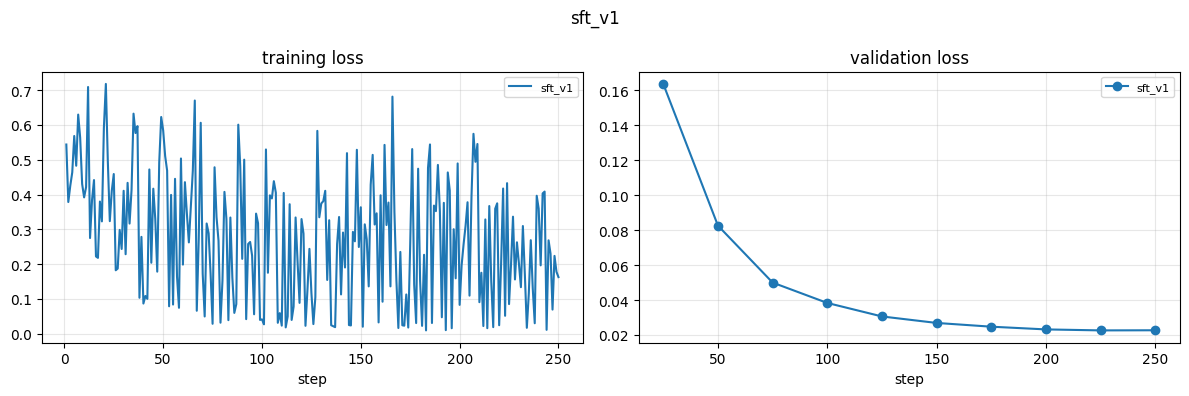

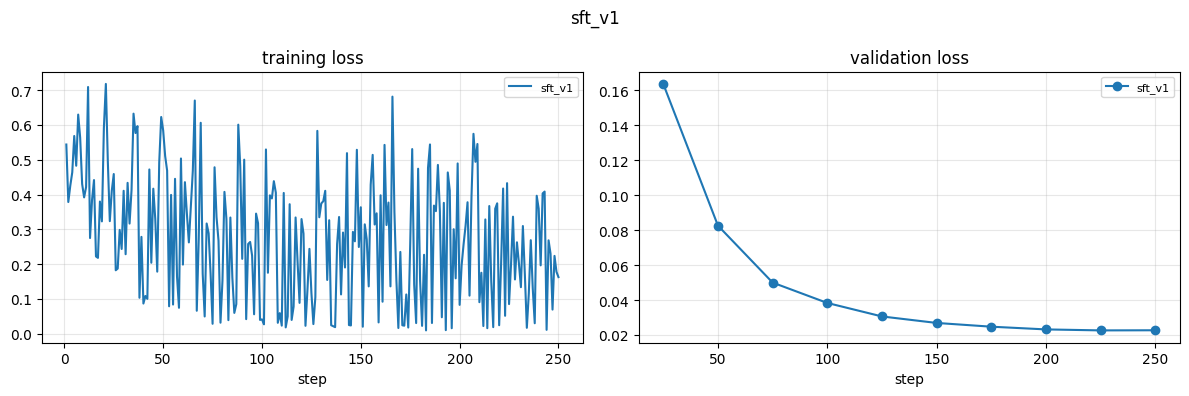

In [32]:
sprint.plot_losses(["sft_v1"], title="sft_v1", save_as="loss_sft_v1.png")
# Optional live view:  %load_ext tensorboard  then  %tensorboard --logdir runs

In [33]:
# ---- Phase 4 checks
sft_val = json.load(open("reports/sft_v1_val.json"))
h = sprint.loss_history("runs/sft_v1")
tr = [l for _, l in h["train"]]; va = [l for _, l in h["eval"]]
falls = len(tr) > 1 and tr[-1] < tr[0]
rising = len(va) > 2 and va[-1] > min(va) * 1.02
check("4.1", falls if not rising else None,
      f"train loss {tr[0] if tr else None} -> {tr[-1] if tr else None}; "
      f"val loss min {min(va) if va else None}, last {va[-1] if va else None}"
      + ("  — val loss rose at the end: note for Phase 5 (epochs)" if rising else ""))
p = sft_val["paired_a_minus_b"]
check("4.2", p["exact_match_diff"] > 0 and p["ci95"][0] > 0,
      f"exact_match {sft_val['metrics']['exact_match']}% vs base: {p['exact_match_diff']:+} points, CI95={p['ci95']}")
check("4.3", sft_val["metrics"]["parse_strict"] >= 95, f"parse_strict={sft_val['metrics']['parse_strict']}%")
g = sft_val["groups"]
gap = g["complete"]["exact_match"] - g["missing_field"]["exact_match"]
check("4.4", gap <= 15, f"complete={g['complete']['exact_match']}%, missing_field={g['missing_field']['exact_match']}% (gap {gap:.1f})")
sprint.show_errors("sft_v1", "val", n=20)
check("4.5", None, f"error types: {list(sft_val['error_types'].items())[:6]} — name the cause of each of the 20 above")

✅ PASS   4.1   train loss 0.543803334236145 -> 0.16269300878047943; val loss min 0.022625694051384926, last 0.02269934117794037
✅ PASS   4.2   exact_match 65.33% vs base: +65.33 points, CI95=[59.67, 70.67]
✅ PASS   4.3   parse_strict=100.0%
✅ PASS   4.4   complete=67.89%, missing_field=58.54% (gap 9.4)
104 failed rows in /content/drive/MyDrive/soup-sprint/reports/sft_v1_val.errors.jsonl; showing 20
- [intent_wrong,date_wrong] today=2026-04-03 | Hold Room A for us the day after tomorrow at 13:45.
    gold: {"intent": "book", "date": "2026-04-05", "time": "13:45", "resource": "Room A", "needs_clarification": false}
    got : '{"intent": "reschedule", "date": "2026-04-06", "time": "13:45", "resource": "Room A", "needs_clarification": false}'
- [intent_wrong] today=2026-11-13 | Something came up, can we do on 2026-11-19 at 6:30 pm instead for my Court 2 reservation?
    gold: {"intent": "reschedule", "date": "2026-11-19", "time": "18:30", "resource": "Court 2", "needs_clarification": false

False

## Phase 5 — Hyperparameter study (≈ 2–4 h, ~1–1.5 h of GPU)

One factor at a time, **validation set only**. Each run gets its own config and `runs/<name>/`; re-running a
cell skips any run whose adapter is already on Drive. Results collect in `reports/hparam_study.csv`.

| Round | Vary | Values | Kept fixed |
|---|---|---|---|
| 1 | learning rate | 5e-5, 1e-4 (= sft_v1), 2e-4 | 2 epochs, rank 16 |
| 2 | epochs | 1, 3 (2 already ran) | best lr, rank 16 |
| 3 | LoRA rank | 8, 32 (alpha = 2 × rank) | best lr and epochs |
| 4 | seed | 7, 123 (42 already ran) | best of everything → run-to-run noise |

**Choosing inside a round:** the best exact_match wins, but any setting within `TIE_POINTS` of the best counts as a
tie and the cheaper one is chosen (fewer epochs, smaller rank). Round 4 measures the real noise; if it is bigger
than `TIE_POINTS`, revisit the earlier picks with that number.

| # | Check | Pass when |
|---|---|---|
| 5.1 | All runs scored | 9 rows in the study table, each with exact_match and CI95 |
| 5.2 | Learning rate | 2e-4 learns fastest (may be noisier); 5e-5 may underfit in 2 epochs |
| 5.3 | Epochs | val loss is lowest near the best epoch count |
| 5.4 | Noise | the 3 seeds agree within a few points (≤ 5) |
| 5.5 | Frozen choice | `BEST_RUN` written to `reports/best_run.json` **before** any test-set run |

In [34]:
TIE_POINTS = 2.0  # differences smaller than this are ties (update after round 4)

def study():
    import pandas as pd
    return pd.read_csv("reports/hparam_study.csv")

def pick(names, prefer=None):
    """Best exact_match among `names`; within TIE_POINTS, prefer the smallest value of `prefer`."""
    df = study().set_index("run").loc[names]
    best = df["exact_match"].max()
    ties = df[df["exact_match"] >= best - TIE_POINTS]
    choice = ties.sort_values(prefer).index[0] if prefer else df["exact_match"].idxmax()
    print(df[["lr", "epochs", "rank", "seed", "exact_match", "ci_lo", "ci_hi", "min_val_loss", "last_val_loss"]])
    print(f"-> pick {choice} (ties within {TIE_POINTS} pts: {list(ties.index)})")
    return choice

def name_lr(lr):
    return f"lr_{lr}"

### Round 1 — learning rate

skip training lr_5e-05: adapter already at /content/drive/MyDrive/soup-sprint/runs/lr_5e-05
skip predict lr_5e-05/val: /content/drive/MyDrive/soup-sprint/reports/preds/lr_5e-05_val.pred.jsonl exists
lr_5e-05/val: exact_match=37.67% CI95=[32.0, 43.0] schema_valid=97.67% parse_strict=100.0% parse_lenient=100.0%
  vs base: +37.67 points, CI95=[32.0, 43.0]
  groups: {'intent=book': 32.89, 'intent=reschedule': 19.12, 'intent=cancel': 47.89, 'intent=check': 48.24, 'complete': 43.58, 'missing_field': 21.95}
  top errors: [('needs_clarification_wrong', 67), ('date_wrong', 65), ('time_wrong', 55), ('intent_wrong', 44), ('date_invented', 14), ('resource_wrong', 10)]
skip training lr_0.0002: adapter already at /content/drive/MyDrive/soup-sprint/runs/lr_0.0002
skip predict lr_0.0002/val: /content/drive/MyDrive/soup-sprint/reports/preds/lr_0.0002_val.pred.jsonl exists
lr_0.0002/val: exact_match=73.33% CI95=[68.33, 78.33] schema_valid=99.0% parse_strict=100.0% parse_lenient=100.0%
  vs base: +73.33 

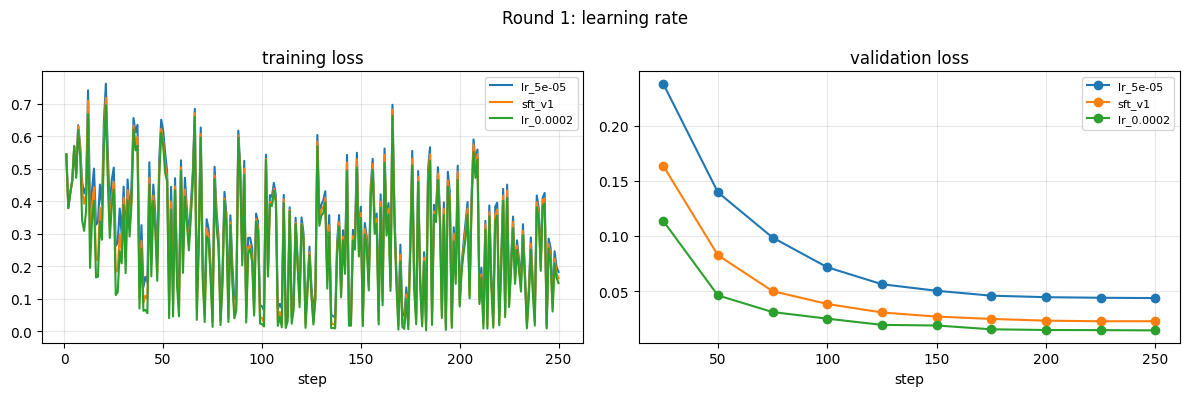

BEST_LR = 0.0002


In [35]:
for lr in [5e-5, 2e-4]:
    sprint.run(name_lr(lr), {"training": {"lr": lr}}, round_="1-lr")
R1 = ["lr_5e-05", "sft_v1", "lr_0.0002"]
best_r1 = pick(R1)
BEST_LR = float(study().set_index("run").loc[best_r1, "lr"])
sprint.plot_losses(R1, title="Round 1: learning rate", save_as="loss_round1.png")
print("BEST_LR =", BEST_LR)

### Round 2 — epochs

skip training ep_1: adapter already at /content/drive/MyDrive/soup-sprint/runs/ep_1
skip predict ep_1/val: /content/drive/MyDrive/soup-sprint/reports/preds/ep_1_val.pred.jsonl exists
ep_1/val: exact_match=55.0% CI95=[49.33, 60.33] schema_valid=98.67% parse_strict=100.0% parse_lenient=100.0%
  vs base: +55.0 points, CI95=[49.33, 60.33]
  groups: {'intent=book': 48.68, 'intent=reschedule': 33.82, 'intent=cancel': 71.83, 'intent=check': 63.53, 'complete': 61.47, 'missing_field': 37.8}
  top errors: [('date_wrong', 54), ('needs_clarification_wrong', 42), ('intent_wrong', 36), ('time_wrong', 31), ('date_missed', 2), ('time_invented', 1)]
skip training ep_3: adapter already at /content/drive/MyDrive/soup-sprint/runs/ep_3
skip predict ep_3/val: /content/drive/MyDrive/soup-sprint/reports/preds/ep_3_val.pred.jsonl exists
ep_3/val: exact_match=78.0% CI95=[73.0, 82.67] schema_valid=99.0% parse_strict=100.0% parse_lenient=100.0%
  vs base: +78.0 points, CI95=[73.0, 82.67]
  groups: {'intent=book':

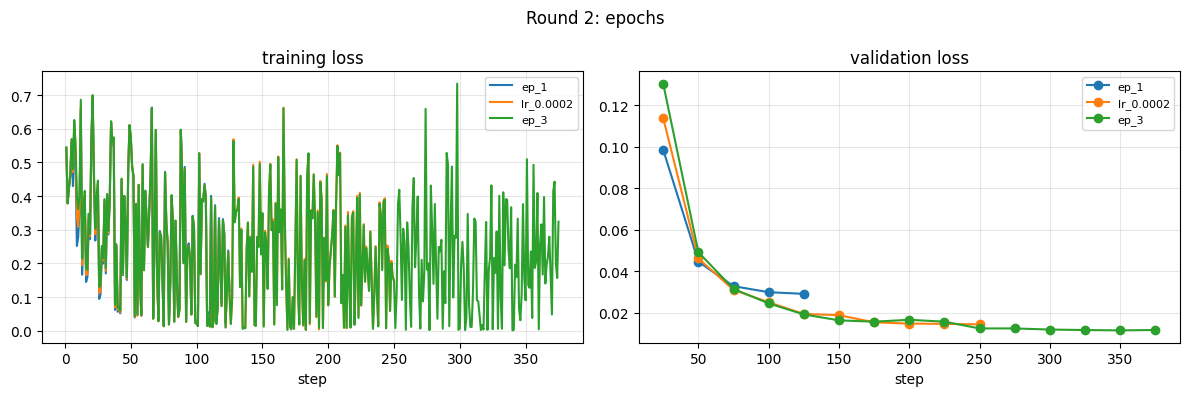

BEST_EPOCHS = 3


In [36]:
for ep in [1, 3]:
    sprint.run(f"ep_{ep}", {"training": {"lr": BEST_LR, "epochs": ep}}, round_="2-epochs")
R2 = ["ep_1", best_r1, "ep_3"]
best_r2 = pick(R2, prefer="epochs")
BEST_EPOCHS = int(study().set_index("run").loc[best_r2, "epochs"])
sprint.plot_losses(R2, title="Round 2: epochs", save_as="loss_round2.png")
print("BEST_EPOCHS =", BEST_EPOCHS)

### Round 3 — LoRA rank

In [37]:
for r in [8, 32]:
    sprint.run(f"r_{r}", {"training": {"lr": BEST_LR, "epochs": BEST_EPOCHS, "lora": {"r": r, "alpha": 2 * r}}},
               round_="3-rank")
R3 = ["r_8", best_r2, "r_32"]
best_r3 = pick(R3, prefer="rank")
BEST_RANK = int(study().set_index("run").loc[best_r3, "rank"])
print("BEST_RANK =", BEST_RANK, "| best config so far:", best_r3)

skip training r_8: adapter already at /content/drive/MyDrive/soup-sprint/runs/r_8
skip predict r_8/val: /content/drive/MyDrive/soup-sprint/reports/preds/r_8_val.pred.jsonl exists
r_8/val: exact_match=57.67% CI95=[52.0, 62.67] schema_valid=99.0% parse_strict=100.0% parse_lenient=100.0%
  vs base: +57.67 points, CI95=[52.0, 62.67]
  groups: {'intent=book': 52.63, 'intent=reschedule': 30.88, 'intent=cancel': 81.69, 'intent=check': 63.53, 'complete': 61.01, 'missing_field': 48.78}
  top errors: [('date_wrong', 52), ('intent_wrong', 49), ('needs_clarification_wrong', 22), ('time_wrong', 21), ('time_invented', 3), ('date_missed', 1)]
skip training r_32: adapter already at /content/drive/MyDrive/soup-sprint/runs/r_32
skip predict r_32/val: /content/drive/MyDrive/soup-sprint/reports/preds/r_32_val.pred.jsonl exists
r_32/val: exact_match=67.33% CI95=[62.0, 72.33] schema_valid=99.33% parse_strict=100.0% parse_lenient=100.0%
  vs base: +67.33 points, CI95=[62.0, 72.33]
  groups: {'intent=book': 6

### Round 4 — seeds (run-to-run noise)

In [38]:
best_over = {"training": {"lr": BEST_LR, "epochs": BEST_EPOCHS, "lora": {"r": BEST_RANK, "alpha": 2 * BEST_RANK}}}
for seed in [7, 123]:
    sprint.run(f"best_seed{seed}", sprint.deep_merge(best_over, {"training": {"seed": seed}}), round_="4-seed",
               notes="noise check")
R4 = [best_r3, "best_seed7", "best_seed123"]
df4 = study().set_index("run").loc[R4]
NOISE = float(df4["exact_match"].max() - df4["exact_match"].min())
print(df4[["seed", "exact_match", "ci_lo", "ci_hi"]]); print(f"seed spread = {NOISE:.1f} points")

skip training best_seed7: adapter already at /content/drive/MyDrive/soup-sprint/runs/best_seed7
skip predict best_seed7/val: /content/drive/MyDrive/soup-sprint/reports/preds/best_seed7_val.pred.jsonl exists
best_seed7/val: exact_match=66.33% CI95=[61.0, 71.33] schema_valid=99.33% parse_strict=100.0% parse_lenient=100.0%
  vs base: +66.33 points, CI95=[61.0, 71.33]
  groups: {'intent=book': 61.84, 'intent=reschedule': 33.82, 'intent=cancel': 88.73, 'intent=check': 77.65, 'complete': 67.89, 'missing_field': 62.2}
  top errors: [('intent_wrong', 51), ('date_wrong', 42), ('needs_clarification_wrong', 12), ('time_wrong', 7), ('resource_wrong', 3), ('time_invented', 2)]
skip training best_seed123: adapter already at /content/drive/MyDrive/soup-sprint/runs/best_seed123
skip predict best_seed123/val: /content/drive/MyDrive/soup-sprint/reports/preds/best_seed123_val.pred.jsonl exists
best_seed123/val: exact_match=65.67% CI95=[60.0, 70.67] schema_valid=98.67% parse_strict=100.0% parse_lenient=10

In [39]:
# ---- Phase 5 checks
df = study()
nine = ["sft_v1", "lr_5e-05", "lr_0.0002", "ep_1", "ep_3", "r_8", "r_32", "best_seed7", "best_seed123"]
have = [n for n in nine if n in set(df["run"])]
check("5.1", len(have) == 9 and df.set_index("run").loc[have, ["ci_lo", "ci_hi"]].notna().all().all(),
      f"{len(have)}/9 study runs scored: missing {sorted(set(nine) - set(have))}")
s = df.set_index("run")
check("5.2", None, "exact_match / final train loss by lr: " + ", ".join(
      f"{n}: {s.loc[n, 'exact_match']}% / {s.loc[n, 'final_train_loss']:.3f}" for n in R1))
check("5.3", None, "val loss (min / last) by epochs: " + ", ".join(
      f"{s.loc[n, 'epochs']}ep: {s.loc[n, 'min_val_loss']:.3f} / {s.loc[n, 'last_val_loss']:.3f}" for n in R2))
check("5.4", NOISE <= 5, f"seed spread {NOISE:.1f} points (TIE_POINTS was {TIE_POINTS})"
      + ("; earlier picks that differ by less than this are ties" if NOISE > TIE_POINTS else ""))
print(df.to_string())

✅ PASS   5.1   9/9 study runs scored: missing []
👀 REVIEW 5.2   exact_match / final train loss by lr: lr_5e-05: 37.67% / 0.182, sft_v1: 65.33% / 0.163, lr_0.0002: 73.33% / 0.148
👀 REVIEW 5.3   val loss (min / last) by epochs: 1ep: 0.029 / 0.029, 2ep: 0.014 / 0.014, 3ep: 0.011 / 0.012
❌ FAIL   5.4   seed spread 12.3 points (TIE_POINTS was 2.0); earlier picks that differ by less than this are ties
      round           run       lr  epochs  rank  seed  exact_match  ci_lo  ci_hi  schema_valid  parse_strict  missing_group  final_train_loss  min_val_loss  last_val_loss  train_seconds backend
0      1-lr        sft_v1  0.00010       2    16    42        65.33  59.67  70.67         99.00         100.0          58.54          0.162693      0.022626       0.022699          117.4      hf
1      1-lr      lr_5e-05  0.00005       2    16    42        37.67  32.00  43.00         97.67         100.0          21.95          0.182098      0.043667       0.043667          118.3      hf
2      1-lr     

### Freeze `BEST_RUN` — before any test-set run

`BEST_RUN` defaults to the round-3 winner (seed 42). Change it here if the tables above argue for something else
(e.g. a cheaper setting that ties). Once the test set has been run, this cell refuses to change it.

In [40]:
BEST_RUN = best_r3   # edit if you choose differently

import time
if os.path.exists("reports/test_lock.json"):
    frozen = json.load(open("reports/best_run.json"))
    assert frozen["run"] == BEST_RUN, f"test set already run with {frozen['run']}; BEST_RUN cannot change now"
    print("already frozen:", frozen)
else:
    row = study().set_index("run").loc[BEST_RUN]
    frozen = {"run": BEST_RUN, "frozen_at": time.strftime("%Y-%m-%d %H:%M:%S"),
              "lr": float(row["lr"]), "epochs": int(row["epochs"]), "rank": int(row["rank"]), "seed": int(row["seed"]),
              "val_exact_match": float(row["exact_match"]), "seed_noise_points": NOISE}
    json.dump(frozen, open("reports/best_run.json", "w"), indent=2)
    print("frozen:", frozen)
check("5.5", os.path.exists("reports/best_run.json"), f"BEST_RUN={BEST_RUN} frozen at {frozen['frozen_at']}")

already frozen: {'run': 'ep_3', 'frozen_at': '2026-11-11 14:50:23', 'lr': 0.0002, 'epochs': 3, 'rank': 16, 'seed': 42, 'val_exact_match': 78.0, 'seed_noise_points': 12.329999999999998}
✅ PASS   5.5   BEST_RUN=ep_3 frozen at 2026-11-11 14:50:23


True

## Phase 6 — Final test, general-skills check, export (≈ 2–3 h)

After a reconnect, run Phase 0's install and *Load the helpers* cells, then continue here.

**Steps:** 1) answers on **test** and **stress** from `BEST_RUN` and from the base model, scored as a pair (run once),
2) IFEval + HellaSwag with `lm-eval` on base and tuned, 3) optional merge + GGUF export, 4) results summary,
5) **Runtime → Disconnect and delete runtime**.

**Acceptance checks (set before seeing test results)**

| # | Check | Pass when |
|---|---|---|
| 6.1 | Task win | test exact_match beats base by ≥ 10 points and the paired CI95 is entirely above 0 |
| 6.2 | Format | parse_strict ≥ 95% on test |
| 6.3 | Robustness | stress exact_match within ~15 points of test |
| 6.4 | No forgetting | IFEval and HellaSwag each drop ≤ 5 points from base |
| 6.5 | Honest process | test was run once, after `BEST_RUN` was frozen |

If 6.1 fails, read the errors file before changing anything — most fixes are in the data, not the hyperparameters.

In [41]:
import time
frozen = json.load(open("reports/best_run.json"))
BEST_RUN = frozen["run"]
lock_path = "reports/test_lock.json"
if not os.path.exists(lock_path):
    json.dump({"run": BEST_RUN, "first_test_at": time.strftime("%Y-%m-%d %H:%M:%S"),
               "best_frozen_at": frozen["frozen_at"]}, open(lock_path, "w"), indent=2)
lock = json.load(open(lock_path))
print("lock:", lock)

final = {}
for split in ["test", "stress"]:
    sprint.predict("base", split)                              # skipped if already done
    sprint.predict(BEST_RUN, split, adapter_run=BEST_RUN)      # skipped if already done
    final[split] = sprint.score(BEST_RUN, split, vs="base")
    sprint.log_result(f"FINAL {BEST_RUN}", split, final[split], frozen, notes="vs base, paired")

lock: {'run': 'ep_3', 'first_test_at': '2026-11-11 14:50:23', 'best_frozen_at': '2026-11-11 14:50:23'}
skip predict base/test: /content/drive/MyDrive/soup-sprint/reports/preds/base_test.pred.jsonl exists
skip predict ep_3/test: /content/drive/MyDrive/soup-sprint/reports/preds/ep_3_test.pred.jsonl exists
ep_3/test: exact_match=86.67% CI95=[82.67, 90.33] schema_valid=99.0% parse_strict=100.0% parse_lenient=100.0%
  vs base: +85.67 points, CI95=[81.67, 89.33]
  groups: {'intent=book': 85.71, 'intent=reschedule': 79.69, 'intent=cancel': 92.0, 'intent=check': 88.1, 'complete': 83.33, 'missing_field': 90.28}
  top errors: [('date_wrong', 34), ('intent_wrong', 4), ('needs_clarification_wrong', 1), ('time_wrong', 1)]
skip predict base/stress: /content/drive/MyDrive/soup-sprint/reports/preds/base_stress.pred.jsonl exists
skip predict ep_3/stress: /content/drive/MyDrive/soup-sprint/reports/preds/ep_3_stress.pred.jsonl exists
ep_3/stress: exact_match=44.0% CI95=[36.0, 52.67] schema_valid=89.33% p

In [42]:
# ---- 6.1-6.3, 6.5
t, st = final["test"], final["stress"]
p = t["paired_a_minus_b"]
check("6.1", p["exact_match_diff"] >= 10 and p["ci95"][0] > 0,
      f"test exact_match {t['metrics']['exact_match']}% vs base {t['b']['metrics']['exact_match']}%: "
      f"{p['exact_match_diff']:+} points, CI95={p['ci95']}")
check("6.2", t["metrics"]["parse_strict"] >= 95, f"test parse_strict={t['metrics']['parse_strict']}%")
gap = t["metrics"]["exact_match"] - st["metrics"]["exact_match"]
check("6.3", gap <= 15, f"test {t['metrics']['exact_match']}% vs stress {st['metrics']['exact_match']}% (gap {gap:.1f})")
check("6.5", lock["run"] == BEST_RUN and lock["best_frozen_at"] == frozen["frozen_at"],
      f"test first run at {lock['first_test_at']} with {lock['run']}; BEST_RUN frozen at {frozen['frozen_at']}")
if p["exact_match_diff"] < 10:
    sprint.show_errors(BEST_RUN, "test", n=20)

✅ PASS   6.1   test exact_match 86.67% vs base 1.0%: +85.67 points, CI95=[81.67, 89.33]
✅ PASS   6.2   test parse_strict=100.0%
❌ FAIL   6.3   test 86.67% vs stress 44.0% (gap 42.7)
✅ PASS   6.5   test first run at 2026-11-11 14:50:23 with ep_3; BEST_RUN frozen at 2026-11-11 14:50:23


### General-skills regression (lm-eval)

IFEval (instruction following, with the chat template) and HellaSwag (general, log-likelihood, no template),
base vs base + adapter. Set `LM_EVAL_LIMIT` to e.g. 500 for a faster, noisier estimate.

In [43]:
!pip -q install "lm-eval[ifeval]"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [44]:
import glob
LM_EVAL_LIMIT = None
TASKS = {"ifeval": ("prompt_level_strict_acc,none", True), "hellaswag": ("acc_norm,none", False)}

def lm_eval(tag, adapter_run=None):
    scores = {}
    for task, (metric, chat) in TASKS.items():
        out = f"reports/lm_eval/{tag}_{task}"
        if not glob.glob(f"{out}/**/results_*.json", recursive=True):
            args = f"pretrained={sprint.BASE},dtype=bfloat16"
            if adapter_run:
                args += f",peft={sprint.find_adapter(os.path.join('runs', adapter_run))}"
            cmd = [sys.executable, "-m", "lm_eval", "--model", "hf", "--model_args", args, "--tasks", task,
                   "--batch_size", "auto", "--output_path", out, "--seed", "0"]
            if chat:
                cmd.append("--apply_chat_template")
            if LM_EVAL_LIMIT:
                cmd += ["--limit", str(LM_EVAL_LIMIT)]
            sprint.sh(cmd, log=f"logs/lm_eval_{tag}_{task}.log")
        res = json.load(open(sorted(glob.glob(f"{out}/**/results_*.json", recursive=True))[-1]))
        scores[task] = round(100 * res["results"][task][metric], 2)
    return scores

lm_base = lm_eval("base")
lm_best = lm_eval("best", adapter_run=BEST_RUN)
print("base:", lm_base, "\nbest:", lm_best)
json.dump({"base": lm_base, "best": lm_best, "run": BEST_RUN}, open("reports/lm_eval_summary.json", "w"), indent=2)

$ /usr/bin/python3 -m lm_eval --model hf --model_args pretrained=HuggingFaceTB/SmolLM2-360M-Instruct,dtype=bfloat16 --tasks ifeval --batch_size auto --output_path reports/lm_eval/base_ifeval --seed 0 --apply_chat_template
2026-11-11:15:04:44 INFO     [config.evaluate_config:357] Using default fewshot_as_multiturn=True.
2026-11-11:15:04:54 INFO     [_cli.run:392] Selected Tasks: ['ifeval']
2026-11-11:15:04:56 INFO     [evaluator:214] Setting random seed to 0 | Setting numpy seed to 0 | Setting torch manual seed to 0 | Setting fewshot manual seed to 0
2026-11-11:15:04:56 INFO     [evaluator:239] Initializing hf model, with arguments: {'pretrained': 'HuggingFaceTB/SmolLM2-360M-Instruct', 'dtype': 'bfloat16'}
2026-11-11:15:04:59 INFO     [models.huggingface:289] Using device 'cuda:0'
2026-11-11:15:05:01 INFO     [models.huggingface:582] Model parallel was set to False, max memory was not set, and device map was set to {'': 'cuda:0'}

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 

In [45]:
# ---- 6.4
drops = {k: round(lm_base[k] - lm_best[k], 2) for k in TASKS}
check("6.4", all(d <= 5 for d in drops.values()),
      "drop in points (base - tuned): " + ", ".join(f"{k} {lm_base[k]} -> {lm_best[k]} ({d:+})" for k, d in drops.items()))

✅ PASS   6.4   drop in points (base - tuned): ifeval 33.09 -> 31.61 (+1.48), hellaswag 56.74 -> 57.04 (-0.3)


True

### Export (optional)

Merges the adapter into the base model and exports a `q4_k_m` GGUF (runs on a GTX 1650 laptop or CPU).
Uses `soup merge` / `soup export`; if `soup merge` fails, peft's `merge_and_unload` is used instead.

In [46]:
import glob
RUN_EXPORT = False
if RUN_EXPORT:
    merged = "runs/merged"
    rc, _ = sprint.sh(["soup", "merge", "--adapter", sprint.find_adapter(f"runs/{BEST_RUN}"), "--output", merged],
                      check_rc=False)
    if rc != 0:
        import torch
        from peft import PeftModel
        from transformers import AutoModelForCausalLM, AutoTokenizer
        m = AutoModelForCausalLM.from_pretrained(sprint.BASE, torch_dtype=torch.bfloat16)
        m = PeftModel.from_pretrained(m, sprint.find_adapter(f"runs/{BEST_RUN}")).merge_and_unload()
        m.save_pretrained(merged); AutoTokenizer.from_pretrained(sprint.BASE).save_pretrained(merged)
    rc, _ = sprint.sh(["soup", "export", "--model", merged, "--format", "gguf", "--quant", "q4_k_m",
                       "--output", "exports"], check_rc=False)
    ggufs = glob.glob("exports/**/*.gguf", recursive=True) + glob.glob(f"{merged}/**/*.gguf", recursive=True)
    check("6.x", bool(ggufs), f"GGUF files: {ggufs} (soup export exit {rc})")

### Results log and check summary

In [47]:
lm = json.load(open("reports/lm_eval_summary.json")) if os.path.exists("reports/lm_eval_summary.json") else None
log = sprint.table("results_log")
lines = ["# Results — SmolLM2-360M booking JSON", "",
         f"BEST_RUN: `{BEST_RUN}` (frozen {frozen['frozen_at']}); backend: {sprint.get_backend()}", "",
         "All scores are % on the validation set except the FINAL rows.", "", log.to_markdown(index=False), "",
         "## Hyperparameter study", "", sprint.table("hparam_study").to_markdown(index=False), ""]
if lm:
    lines += ["## General skills (lm-eval)", "", "| task | base | tuned | Δ |", "|---|---|---|---|"]
    lines += [f"| {k} | {lm['base'][k]} | {lm['best'][k]} | {lm['best'][k] - lm['base'][k]:+.2f} |" for k in lm["base"]]
open("reports/RESULTS.md", "w").write("\n".join(lines))
print("\n".join(lines))
print()
sprint.checks_summary()

# Results — SmolLM2-360M booking JSON

BEST_RUN: `ep_3` (frozen 2026-11-11 14:50:23); backend: soup

All scores are % on the validation set except the FINAL rows.

| run          | split   | lr     | epochs   | rank   | seed   |   exact_match | ci95           |   schema_valid |   parse_strict | notes                           | paired_diff                   |
|:-------------|:--------|:-------|:---------|:-------|:-------|--------------:|:---------------|---------------:|---------------:|:--------------------------------|:------------------------------|
| base         | val     | —      | —        | —      | —      |          0    | [0.0, 0.0]     |          48    |            100 | untouched SmolLM2-360M-Instruct | nan                           |
| smoke        | val     | 0.0001 | 1        | 16     | 42     |          0.33 | [0.0, 1.0]     |          55    |            100 | 200 rows; backend=soup          | +0.33 [0.0, 1.0] vs base      |
| sft_v1       | val     | 0.0001 | 2       

**Done → Runtime → Disconnect and delete runtime** to stop using compute units.
Everything (data, configs, adapters, predictions, reports, `RESULTS.md`) is in `MyDrive/soup-sprint/`.